# Practical Session 11b &mdash; t-SNE and UMAP

**Companion to Lecture&nbsp;11.** Second of two notebooks for Session&nbsp;11.

| # | Notebook | Topic |
|---|----------|-------|
| 11a | PCA, LDA and the factorizations | the linear methods: PCA, LDA, factor analysis, NMF |
| **11b** | **t-SNE and UMAP** | **kernel PCA, perplexity, the Student-$t$ kernel, the warnings, UMAP's two steps, ICA (this notebook)** |

PCA can only **rotate and project**: it fits a *flat* subspace through the cloud. This notebook
starts where that runs out &mdash; data lying on a curved surface &mdash; and then takes apart the two
methods that produce the picture at the front of half the papers you will read: **t-SNE** and
**UMAP**.

Both are *visualization* methods, and both come with warnings. The warnings are usually passed
along as folklore ("cluster sizes mean nothing"). Here we **measure** each one instead, on data
whose true sizes and true gaps we chose ourselves.

> &#11088; **Key idea.** t-SNE and UMAP do not preserve distances. They preserve
> **neighborhoods**, and they pay for that by giving up everything else: cluster sizes, the gaps
> between clusters, and the coordinates themselves. A map of this kind is evidence about *who is
> near whom*, and about very little else.

> &#9888;&#65039; **`umap-learn` is not installed in this environment** (nor `numba`, nor
> `pynndescent`). That is not an obstacle: UMAP's pipeline is about fifty lines of NumPy, and
> &sect;8 writes it out. The evidence that it is the real algorithm and not a cartoon is that the
> curve it fits for `min_dist = 0.1` comes out at $a=1.5769$, $b=0.8951$ against the package's
> published $1.577$ and $0.895$ &mdash; a check the cell prints.

*Run each cell (Shift+Enter). Self-contained and offline.*

In [1]:

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

from scipy.spatial.distance import pdist
from scipy.spatial import procrustes
from scipy.stats import spearmanr
from scipy.optimize import curve_fit

from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs, make_circles, make_swiss_roll
from sklearn.decomposition import PCA, KernelPCA, FastICA
from sklearn.manifold import (MDS, TSNE, Isomap, LocallyLinearEmbedding, SpectralEmbedding,
                              trustworthiness)
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

from nb_utils import use_style
from nb_data import make_uneven_clusters, best_1d_threshold_accuracy

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP, CX = "#CC79A7", "0.62"                 # a fifth color, and a gray
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette
CLUSTER_COLORS = [C0, C1, CG, CN, CP]

# The two constants that turn "how many blobs would a reader count?" into a number.
# They are a CHOICE, not a fact -- section 4 re-counts everything at other radii.
CLUMP_FACTOR = 3.0        # DBSCAN radius = this many x the map's median nearest-neighbor distance
CLUMP_MIN = 5             # ... and this many points to form a core


def bare(ax):
    "a panel for a 2-D map: no ticks, a light frame, and a faithful aspect ratio"
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_aspect("equal", adjustable="datalim")   # keep the geometry AND a uniform panel size
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(CX); sp.set_linewidth(0.6)


def focus(ax, Z, q=1.0, pad=0.08):
    """A SQUARE window on the central (100-2q)% of a map, per axis -- so that two or three
    strays cannot set the scale for a whole panel. Returns how many points fall outside it."""
    lo, hi = np.percentile(Z, q, axis=0), np.percentile(Z, 100 - q, axis=0)
    c = 0.5 * (lo + hi)                             # the center of the ROBUST box, not the strays
    h = 0.5 * float(np.max(hi - lo)) * (1 + pad)    # one half-width for both axes: a square
    ax.set_aspect("equal", adjustable="box")        # a square window wants a square panel
    ax.set_xlim(c[0] - h, c[0] + h)
    ax.set_ylim(c[1] - h, c[1] + h)
    return int((np.abs(Z - c).max(1) > h).sum())


def scatter2d(ax, Z, lab=None, title="", s=12):
    "a bare 2-D map -- these coordinates have no units, so there are no ticks"
    if lab is None:
        ax.scatter(Z[:, 0], Z[:, 1], s=s, color=CX, alpha=0.85, edgecolor="none")
    else:
        for k in sorted(np.unique(lab)):
            m = lab == k
            ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=0.85, edgecolor="none",
                       color=CLUSTER_COLORS[int(k) % len(CLUSTER_COLORS)])
    bare(ax)
    ax.set_title(title, fontsize=9.5)


def span(vals):
    "'3' when every run agreed, '28-29' when they did not"
    lo, hi = int(min(vals)), int(max(vals))
    return f"{lo}" if lo == hi else f"{lo}-{hi}"


def knn_sets(Z, k=10):
    "the index set of each point's k nearest neighbors"
    return [set(r) for r in
            NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)[1][:, 1:]]


def knn_overlap(A, B):
    "what fraction of each point's neighbor set survives, averaged over points"
    return float(np.mean([len(a & b) / len(a) for a, b in zip(A, B)]))


def spreads(Z, lab):
    "mean distance from each cluster's own center -- how BIG each cluster looks"
    return [float(np.linalg.norm(Z[lab == k] - Z[lab == k].mean(0), axis=1).mean())
            for k in sorted(np.unique(lab))]


def clump_labels(Z, factor=CLUMP_FACTOR, min_samples=CLUMP_MIN):
    "DBSCAN's labels on a map (-1 is its noise label), so a figure can show what was counted"
    d = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z)[0][:, 1]
    return DBSCAN(eps=factor * np.median(d), min_samples=min_samples).fit_predict(Z)


def clumps(Z, factor=CLUMP_FACTOR, min_samples=CLUMP_MIN):
    "how many separate blobs the eye would count -- DBSCAN (Session 10b, section 1) as the eye"
    return int(len(set(clump_labels(Z, factor, min_samples).tolist()) - {-1}))


def scatter_clumps(ax, Z, lab, title="", s=12):
    "a map colored by what the clump detector found; its noise label -1 is drawn gray"
    for k in sorted(set(lab.tolist())):
        m = lab == k
        ax.scatter(Z[m, 0], Z[m, 1], s=s, alpha=0.9, edgecolor="none",
                   color=CX if k < 0 else CLUSTER_COLORS[int(k) % len(CLUSTER_COLORS)])
    bare(ax)
    ax.set_title(title, fontsize=9.5)


def bbox_area(P):
    "the area of the axis-aligned box a group of points occupies in a map"
    return float((P[:, 0].max() - P[:, 0].min()) * (P[:, 1].max() - P[:, 1].min()))


print("ready")

ready


## 1. When a flat projection is not enough

PCA fits a **flat** subspace: a line, a plane, a hyperplane. If the data lies on a *curved*
surface, no rotation can undo the curvature, and the projection **folds** the surface over
itself &mdash; points that are far apart along the surface land on top of each other.

The standard test case is the **swiss roll**: a 2-D sheet rolled up in 3-D. We generate it
ourselves, so we know each point's true position on the unrolled sheet: its height, and its
distance *along* the roll. For the parametrization $(t\cos t,\;h,\;t\sin t)$ that second
coordinate is the arc length

$$s(t)=\tfrac12\Big(t\sqrt{1+t^2}+\operatorname{arcsinh} t\Big),$$

so we can score any 2-D map against a truth we chose ourselves:

| measure | the question it asks |
|---|---|
| **trustworthiness** ($k=12$) | are the map's neighbors really neighbors *on the sheet*? (**local**) |
| **Spearman $\rho$** between all pairwise distances | does the map get the large-scale geometry right? (**global**) |
| **mean gap** | how far along the sheet is the point the map calls your nearest neighbor? |

**Everything in this section is repeated on five fresh rolls** and reported as mean $\pm$
standard deviation. That is not ceremony. A fourth and very tempting statistic &mdash; the share
of points whose map-neighbor sits more than $20$ units away along the sheet, the outright
**folds** &mdash; is printed at the end of the cell *one column per draw*, and you will watch it
swing from $13.5\%$ to $0.0\%$ for the same method. We look at it, and then we do not quote it.
$\rho$ is what carries the section.

The 20-unit threshold has a scale behind it, which the cell prints first: the sheet is 89 units
long and 21 tall, and one turn of the roll spans 50&ndash;69 units, so a 20-unit gap is not
rounding error &mdash; it means the map has laid one part of the sheet on top of another.

Four methods go in: linear **PCA**, **kernel PCA** with an RBF kernel (Lecture&nbsp;07's trick
applied to PCA &mdash; nonlinear, but still a *projection*), **Isomap** (distances measured
*along* a neighbor graph, and its one knob swept at $6$, $12$ and $20$) and **t-SNE**. The RBF
bandwidth is not tuned; it is the usual median heuristic,
$\gamma=1/\mathrm{median}\lVert\mathbf{x}-\mathbf{x}'\rVert^2$.

The last row of the table is the reference: the raw 3-D data itself, scored the same way. No
2-D map can beat it locally, and its global score is the one PCA inherits.

scale: the sheet is 89 units long and 21 units tall (so a faithful map of it is a 4.2 : 1 strip),
       and one full turn of the roll spans 50 units at the inside and 69 at the outside -- so a 20-unit gap
       is not rounding error, it means the map laid one part of the sheet on another



5 fresh rolls, mean +/- sd. rho is the evidence of this section:
map                         local (trust.)        global (rho)            mean gap
PCA (linear)                0.923 +/-0.040      0.372 +/-0.016       3.55 +/- 2.83
kernel PCA (RBF)            0.845 +/-0.009      0.255 +/-0.008       7.14 +/- 1.29
Isomap (k = 6)              0.998 +/-0.000      0.997 +/-0.002       0.62 +/- 0.03
Isomap (k = 12)             0.971 +/-0.020      0.763 +/-0.064       0.94 +/- 0.53
Isomap (k = 20)             0.933 +/-0.021      0.346 +/-0.036       0.92 +/- 0.94
t-SNE                       0.999 +/-0.000      0.515 +/-0.059       0.57 +/- 0.02
(the 3-D data itself)       0.999 +/-0.001      0.372 +/-0.017       0.58 +/- 0.01

and the tempting fourth statistic we will NOT quote -- the share of points whose
map-neighbor sits more than 20 units away along the sheet, one column per draw:
  map                     seed 0  seed 1  seed 2  seed 3  seed 4      mean +/- sd
  PCA (linear)            

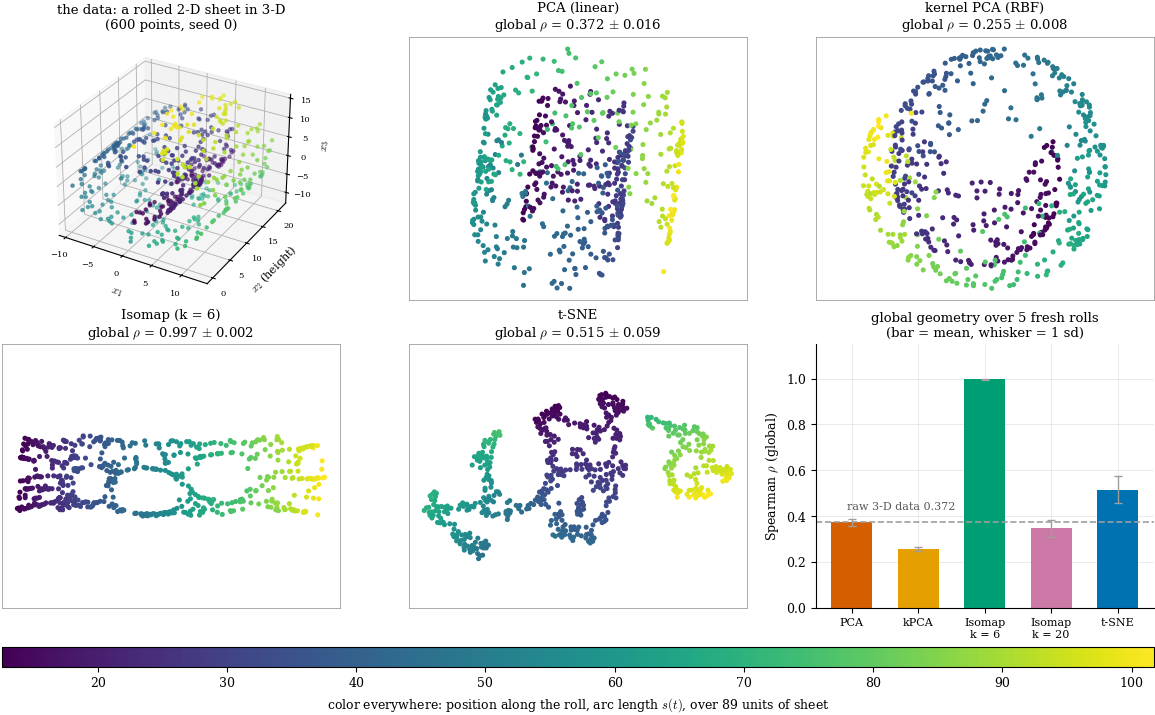

In a good map that color varies smoothly and never mixes.


In [2]:

SEEDS_SR = (0, 1, 2, 3, 4)          # <-- CHANGE ME (every number in this section is over these)
K_ISO = 6                           # the Isomap setting the figure plots (6, 12, 20 are scored)


def roll(seed, n=600):
    "a swiss roll, plus the TRUE unrolled coordinates of every one of its points"
    X, t = make_swiss_roll(n_samples=n, noise=0.05, random_state=seed)
    arc = 0.5 * (t * np.sqrt(1 + t ** 2) + np.arcsinh(t))      # length ALONG the sheet
    return X, t, arc, np.column_stack([arc, X[:, 1]])


def turn_length(u):
    "arc length covered by one full turn (2*pi of the parameter) starting at u"
    f = lambda v: 0.5 * (v * np.sqrt(1 + v ** 2) + np.arcsinh(v))
    return float(f(u + 2 * np.pi) - f(u))


def maps_of(X):
    "the four methods -- Isomap swept at three n_neighbors -- plus the raw data as reference"
    g = 1.0 / np.median(pdist(X) ** 2)                # the median heuristic, not tuned
    return {"PCA (linear)": PCA(n_components=2).fit_transform(X),
            "kernel PCA (RBF)": KernelPCA(n_components=2, kernel="rbf",
                                          gamma=g).fit_transform(X),
            "Isomap (k = 6)": Isomap(n_neighbors=6, n_components=2).fit_transform(X),
            "Isomap (k = 12)": Isomap(n_neighbors=12, n_components=2).fit_transform(X),
            "Isomap (k = 20)": Isomap(n_neighbors=20, n_components=2).fit_transform(X),
            "t-SNE": TSNE(n_components=2, perplexity=30, init="pca",
                          random_state=0).fit_transform(X),
            "(the 3-D data itself)": X}


X_sr, t_sr, arc_sr, sheet_sr = roll(SEEDS_SR[0])
print(f"scale: the sheet is {arc_sr.max() - arc_sr.min():.0f} units long and "
      f"{X_sr[:, 1].max() - X_sr[:, 1].min():.0f} units tall (so a faithful map of it is a "
      f"{(arc_sr.max() - arc_sr.min()) / (X_sr[:, 1].max() - X_sr[:, 1].min()):.1f} : 1 strip),")
print(f"       and one full turn of the roll spans {turn_length(t_sr.min()):.0f} units at the "
      f"inside and {turn_length(t_sr.max() - 2 * np.pi):.0f} at the outside -- so a 20-unit gap")
print("       is not rounding error, it means the map laid one part of the sheet on another")

scores_sr, maps_sr = {}, None
for sd in SEEDS_SR:
    X, t, arc, sheet = roll(sd)
    d_sheet = pdist(sheet)
    mp = maps_of(X)
    for name, Z in mp.items():
        nn = NearestNeighbors(n_neighbors=2).fit(Z).kneighbors(Z)[1][:, 1]
        gap = np.abs(arc - arc[nn])
        scores_sr.setdefault(name, []).append(
            (float(trustworthiness(sheet, Z, n_neighbors=12)),
             float(spearmanr(d_sheet, pdist(Z)).statistic),
             float(gap.mean()), float((gap > 20).mean())))
    if maps_sr is None:
        maps_sr = mp                                   # the seed-0 maps, for the figure


def stat(name, j):
    "the mean and the standard deviation of column j of a map's scores, over the seeds"
    a = np.array([s[j] for s in scores_sr[name]])
    return float(a.mean()), float(a.std(ddof=1))


print(f"\n{len(SEEDS_SR)} fresh rolls, mean +/- sd. rho is the evidence of this section:")
print(f"{'map':22s}{'local (trust.)':>20s}{'global (rho)':>20s}{'mean gap':>20s}")
for name in scores_sr:
    (tm, ts), (rm, rs), (gm, gs) = stat(name, 0), stat(name, 1), stat(name, 2)
    print(f"{name:22s} {tm:10.3f} +/-{ts:5.3f} {rm:10.3f} +/-{rs:5.3f} {gm:10.2f} +/-{gs:5.2f}")

print("\nand the tempting fourth statistic we will NOT quote -- the share of points whose")
print("map-neighbor sits more than 20 units away along the sheet, one column per draw:")
print(f"  {'map':22s}" + "".join(f"{f'seed {s}':>8s}" for s in SEEDS_SR) + f"{'mean +/- sd':>17s}")
for name in scores_sr:
    fo = np.array([s[3] for s in scores_sr[name]])
    print(f"  {name:22s}" + "".join(f"{100 * v:7.1f}%" for v in fo) +
          f"{100 * fo.mean():10.1f}% +/-{100 * fo.std(ddof=1):4.1f}")

fig = plt.figure(figsize=(11.6, 7.2))
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.0, 0.075])
vmin, vmax = arc_sr.min(), arc_sr.max()

ax3 = fig.add_subplot(gs[0, 0], projection="3d")
sc3 = ax3.scatter(*X_sr.T, s=5, c=arc_sr, cmap="viridis", vmin=vmin, vmax=vmax)
ax3.set_title(f"the data: a rolled 2-D sheet in 3-D\n({len(X_sr)} points, seed {SEEDS_SR[0]})",
              fontsize=9.5)
ax3.set_xlabel("$x_1$", fontsize=8, labelpad=-4)
ax3.set_ylabel("$x_2$ (height)", fontsize=8, labelpad=-4)
ax3.set_zlabel("$x_3$", fontsize=8, labelpad=-4)
ax3.tick_params(labelsize=6, pad=-1)

for spec, name in zip((gs[0, 1], gs[0, 2], gs[1, 0], gs[1, 1]),
                      ("PCA (linear)", "kernel PCA (RBF)", f"Isomap (k = {K_ISO})", "t-SNE")):
    ax = fig.add_subplot(spec)
    ax.scatter(maps_sr[name][:, 0], maps_sr[name][:, 1], s=7, c=arc_sr, cmap="viridis",
               vmin=vmin, vmax=vmax)
    bare(ax)
    rm, rs = stat(name, 1)
    ax.set_title(f"{name}\nglobal $\\rho$ = {rm:.3f} $\\pm$ {rs:.3f}", fontsize=9.5)

axb = fig.add_subplot(gs[1, 2])
bars = ["PCA (linear)", "kernel PCA (RBF)", "Isomap (k = 6)", "Isomap (k = 20)", "t-SNE"]
axb.bar(range(len(bars)), [stat(n, 1)[0] for n in bars],
        yerr=[stat(n, 1)[1] for n in bars], capsize=3, width=0.62,
        color=[C1, CN, CG, CP, C0], error_kw=dict(ecolor=CX, lw=1.0))
ref = stat("(the 3-D data itself)", 1)[0]
axb.axhline(ref, color=CX, ls="--", lw=1.2)
axb.text(0.75, ref + 0.055, f"raw 3-D data {ref:.3f}", ha="center", fontsize=8,
         color="0.35")
axb.set_xticks(range(len(bars)),
               ["PCA", "kPCA", "Isomap\nk = 6", "Isomap\nk = 20", "t-SNE"], fontsize=8)
axb.set_ylim(0, 1.15); axb.set_ylabel(r"Spearman $\rho$ (global)", fontsize=9)
axb.set_title(f"global geometry over {len(SEEDS_SR)} fresh rolls\n(bar = mean, whisker = 1 sd)",
              fontsize=9.5)

cb = fig.colorbar(sc3, cax=fig.add_subplot(gs[2, :]), orientation="horizontal")
cb.set_label(f"color everywhere: position along the roll, arc length $s(t)$, over "
             f"{arc_sr.max() - arc_sr.min():.0f} units of sheet", fontsize=9)
plt.show()
print("In a good map that color varies smoothly and never mixes.")

Read that table twice, and read the $\rho$ column first.

* **PCA cannot unroll it, and that is not clumsiness.** Globally PCA scores
  $\rho=0.372\pm0.016$ and the raw 3-D data itself scores $0.372\pm0.017$ &mdash; the same number.
  A projection can only inherit the metric it was handed, and straight-line distance *through* a
  rolled sheet is already a bad measure of distance *along* it. The local damage shows in the gap
  column: PCA's average map-neighbor sits $3.55\pm2.83$ units away along the sheet, against
  $0.58\pm0.01$ in the raw data. Only the methods that work from a neighbor **graph** beat this.
* **The fold is real; the percentage is not quotable.** In the per-seed block PCA folds
  $13.5\%$ of its points on seed 0 and $0.0\%$ on seed 3 &mdash; $5.2\%\pm5.0\%$ over the five
  draws, with seed 0 the *maximum*. One draw would have licensed either "PCA folds one point in
  seven" or "PCA does not fold at all". The same goes for Isomap at $k=20$ ($0.7\%\pm1.5\%$,
  and exactly $0.0\%$ on three draws of five). This is what a single-draw statistic looks like
  when you finally repeat it, and it is why the rest of this notebook repeats everything.
* **Being nonlinear is not enough.** Kernel PCA is nonlinear and it is *worse*: $\rho=0.255\pm0.008$,
  below plain PCA's $0.372$, with a worse local score too ($0.845\pm0.009$ against $0.923\pm0.040$).
  It is also the one map here that folds **reliably** &mdash; $10.6\%\pm2.0\%$, never below
  $8.5\%$ on any draw. A kernel is a fixed similarity function; it has no idea that the roll is a
  sheet, and nothing in it measures distance *along* a surface.
* **Isomap unrolls it &mdash; if its graph is right.** It measures distance along a neighbor
  graph, and at `n_neighbors = 6` it is almost perfect: $\rho=0.997\pm0.002$, trustworthiness
  $0.998\pm0.000$. The sweep shows how fragile that is. At $12$ the graph starts
  **short-circuiting** between neighboring turns of the roll &mdash; two points close in 3-D but a
  winding apart on the sheet get joined &mdash; and $\rho$ falls to $0.763\pm0.064$; at $20$ it is
  $0.346\pm0.036$, no better than PCA. One knob, one assumption, and the assumption is checkable.
* **t-SNE is the best local map and not the best global one.** Trustworthiness $0.999\pm0.000$,
  the same to three decimals as the raw 3-D data's own $0.999\pm0.001$ &mdash; there is nothing
  left to win locally &mdash; while its distance correlation, $0.515\pm0.059$, is far below
  Isomap's $0.997$. Keep that pair of numbers in mind: it is this whole notebook in miniature.
  (On seed 0 *alone* t-SNE's trustworthiness comes out fractionally **above** the raw data's.
  Over five rolls the two are indistinguishable. A third decimal place is not a finding.)
* **The shape of the Isomap panel is evidence, not a drawing accident.** The sheet is $89$ units
  long and $21$ tall, so a faithful map of it is a $4.2:1$ strip. Every panel keeps an equal
  aspect ratio, so Isomap's wide, short band *is* the recovered geometry &mdash; and the roundness
  of the PCA and kernel PCA panels is the fold.

> &#128161; **A plotting note worth keeping.** On a 3-D axis under constrained layout, hiding the
> ticks with `set_xticklabels([])` makes matplotlib warn that the axes collapsed to zero and then
> misalign the row; `set_xticks([])` (and `set_zticks([])`) is the fix. Here we do the opposite
> and keep the ticks and the axis names: a panel claiming "a rolled sheet in 3-D" owes the reader
> a scale and an orientation.

## 2. Kernel PCA: the same Gram matrix, a different job

Kernel PCA deserves its own look, because it *is* Session&nbsp;07 applied to Session&nbsp;11.
Build the $n\times n$ **Gram matrix** $K_{ij}=K(\mathbf{x}_i,\mathbf{x}_j)$, center it, and
eigendecompose **that** instead of the $d\times d$ covariance. The eigenvectors of $K$ give
components that are curved back in the input space, and $\phi$ is never written down. What the
bandwidth $\gamma$ does to such a matrix &mdash; too small and every point resembles every other,
too large and every point becomes its own island &mdash; was measured in Session&nbsp;10b,
section&nbsp;8 (there the two crescents survived only for $\gamma\in[31.6,178]$), and we do not
re-derive it here.

The swiss roll was the wrong test for it. The right one is data that is nonlinear but not a
*manifold* problem: two **concentric rings**, where no straight cut separates the classes and
linear PCA &mdash; a rotation &mdash; cannot help. We measure separability the way Lecture&nbsp;11
and notebook&nbsp;11a (*PCA, LDA and the factorizations*) do: with the best accuracy *any single
threshold* on the first component can reach, so the number describes the **projection** and not a
classifier trained on top of it. 11a's section&nbsp;6 attached a caveat to that statistic, and the
cell below repeats it in measured form rather than quoting it: "best over all thresholds" is a
**maximum over $n-1$ candidate cuts**, so its null is **not** $0.5$, and the cell shuffles the
labels 2000 times to find out what it actually is.

And then the part that is this notebook's own, not Session&nbsp;07's: look at **which ring
collapses**, and by how much. Each ring's area in a map is measured as the area of the box it
occupies &mdash; on five fresh draws, and at four bandwidths.

the null for the threshold statistic on 400 balanced points (2000 shuffles): 0.5423 +/- 0.0132,
  95th percentile 0.5675 -- NOT 0.5000. Compare against that.

best accuracy ANY single threshold on the first component reaches, over 5 fresh draws:
  the raw feature x1                     0.6900 +/- 0.0018
  linear PCA, PC1                        0.6890 +/- 0.0029
  kernel PCA, kPC1 (gamma = 8)           1.0000 +/- 0.0000

and now the warning that is this notebook's, not Session 07's: WHICH RING COLLAPSES.
each ring's area in a picture is the area of the box it occupies --
  outer box / inner box in the data                6.9552 +/- 0.4844
  outer box / inner box in the kernel PCA map      0.0086 +/- 0.0017

so at gamma = 8 the map draws the OUTER ring 119x +/- 19 SMALLER than the inner one
  (87x to 137x over the 5 draws), where in the data the outer ring's box is 6.96x +/- 0.48 BIGGER
  -- a swing of 826x between the truth and the picture.

and the reversal is the bandwidth's doing (Se

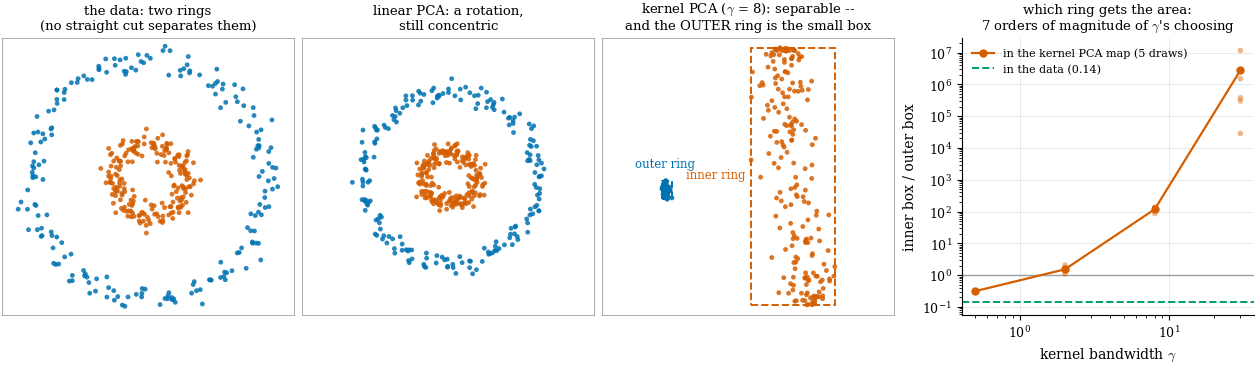

In [3]:

GAMMA_KP = 8.0                      # <-- CHANGE ME (the sweep below covers 0.5 to 30)
SEEDS_KP = (0, 1, 2, 3, 4)          # <-- CHANGE ME (every number in this section is over these)


def rings(seed):
    "two concentric rings: the outer one is the bigger circle, and we will check the map's word"
    return make_circles(n_samples=400, factor=0.3, noise=0.06, random_state=seed)


X_kp, y_kp = rings(SEEDS_KP[0])
lin_kp = PCA(n_components=2).fit_transform(X_kp)
knl_kp = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA_KP).fit_transform(X_kp)

# 11a (section 6) attached a caveat to this statistic: "best accuracy over ALL thresholds" is a
# maximum over n-1 candidate cuts, and a maximum of noise is above the mean of noise. So its
# null is NOT 0.5. Measure the ceiling here, on these 400 points, by shuffling the labels.
rng_kp = np.random.default_rng(0)
null_kp = np.array([best_1d_threshold_accuracy(lin_kp[:, 0], rng_kp.permutation(y_kp))
                    for _ in range(2000)])
print(f"the null for the threshold statistic on {len(y_kp)} balanced points (2000 shuffles): "
      f"{null_kp.mean():.4f} +/- {null_kp.std():.4f},")
print(f"  95th percentile {np.quantile(null_kp, 0.95):.4f} -- NOT 0.5000. Compare against that.")

acc_kp, area_kp = {}, {"the data": [], "the kernel PCA map": []}
for sd in SEEDS_KP:
    X, y = rings(sd)
    L = PCA(n_components=2).fit_transform(X)
    K = KernelPCA(n_components=2, kernel="rbf", gamma=GAMMA_KP).fit_transform(X)
    for nm, z in (("the raw feature x1", X[:, 0]), ("linear PCA, PC1", L[:, 0]),
                  (f"kernel PCA, kPC1 (gamma = {GAMMA_KP:g})", K[:, 0])):
        acc_kp.setdefault(nm, []).append(best_1d_threshold_accuracy(z, y))
    area_kp["the data"].append(bbox_area(X[y == 0]) / bbox_area(X[y == 1]))
    area_kp["the kernel PCA map"].append(bbox_area(K[y == 0]) / bbox_area(K[y == 1]))

print(f"\nbest accuracy ANY single threshold on the first component reaches, "
      f"over {len(SEEDS_KP)} fresh draws:")
for nm, v in acc_kp.items():
    a = np.array(v)
    print(f"  {nm:38s} {a.mean():.4f} +/- {a.std(ddof=1):.4f}")

print(f"\nand now the warning that is this notebook's, not Session 07's: WHICH RING COLLAPSES.")
print("each ring's area in a picture is the area of the box it occupies --")
for nm, v in area_kp.items():
    a = np.array(v)
    print(f"  outer box / inner box in {nm:20s} {a.mean():9.4f} +/- {a.std(ddof=1):.4f}")
inv_kp, dat_kp = 1.0 / np.array(area_kp["the kernel PCA map"]), np.array(area_kp["the data"])
print(f"\nso at gamma = {GAMMA_KP:g} the map draws the OUTER ring {inv_kp.mean():.0f}x +/- "
      f"{inv_kp.std(ddof=1):.0f} SMALLER than the inner one")
print(f"  ({inv_kp.min():.0f}x to {inv_kp.max():.0f}x over the {len(SEEDS_KP)} draws), where in "
      f"the data the outer ring's box is {dat_kp.mean():.2f}x +/- {dat_kp.std(ddof=1):.2f} BIGGER")
print(f"  -- a swing of {dat_kp.mean() * inv_kp.mean():.0f}x between the truth and the picture.")

print(f"\nand the reversal is the bandwidth's doing (Session 10b section 8 measured what gamma")
print("does to a Gram matrix; here we only ask what it does to the AREAS):")
print(f"  {'gamma':>7s} {'inner box / outer box':>26s} {'threshold accuracy':>24s}")
sweep_kp = {}
for g in (0.5, 2.0, 8.0, 30.0):
    rr, aa = [], []
    for sd in SEEDS_KP:
        X, y = rings(sd)
        Z = KernelPCA(n_components=2, kernel="rbf", gamma=g).fit_transform(X)
        rr.append(bbox_area(Z[y == 1]) / bbox_area(Z[y == 0]))
        aa.append(best_1d_threshold_accuracy(Z[:, 0], y))
    sweep_kp[g] = (np.array(rr), np.array(aa))
    print(f"  {g:7.1f} {np.mean(rr):19.4g}x +/-{np.std(rr, ddof=1):-9.3g} "
          f"{np.mean(aa):12.4f} +/- {np.std(aa, ddof=1):.4f}")
gmu = np.array([sweep_kp[g][0].mean() for g in sorted(sweep_kp)])
print(f"\nthat is {np.log10(gmu.max() / gmu.min()):.0f} orders of magnitude of 'area' at "
      f"gamma's choosing, and the comparison")
print("changes SIDES between gamma = 0.5 and gamma = 2. The areas carry no evidence at all.")

fig, axes = plt.subplots(1, 4, figsize=(12.6, 3.7))
scatter2d(axes[0], X_kp, y_kp, "the data: two rings\n(no straight cut separates them)")
scatter2d(axes[1], lin_kp, y_kp, "linear PCA: a rotation,\nstill concentric")
scatter2d(axes[2], knl_kp, y_kp, f"kernel PCA ($\\gamma$ = {GAMMA_KP:g}): separable --\n"
                                 "and the OUTER ring is the small box")
for k, col in ((0, C0), (1, C1)):
    P = knl_kp[y_kp == k]
    axes[2].add_patch(plt.Rectangle((P[:, 0].min(), P[:, 1].min()),
                                    P[:, 0].max() - P[:, 0].min(),
                                    P[:, 1].max() - P[:, 1].min(),
                                    fill=False, edgecolor=col, lw=1.4, ls="--", zorder=4))
P_out, P_inn = knl_kp[y_kp == 0], knl_kp[y_kp == 1]
axes[2].text(P_out[:, 0].mean(), P_out[:, 1].max() + 0.04 * np.ptp(knl_kp[:, 1]), "outer ring",
             color=C0, ha="center", va="bottom", fontsize=8.5)
axes[2].text(P_inn[:, 0].min() - 0.03 * np.ptp(knl_kp[:, 0]), P_inn[:, 1].mean(), "inner ring",
             color=C1, ha="right", va="center", fontsize=8.5)
gam_kp = sorted(sweep_kp)
for g in gam_kp:                              # every draw, so the instability is visible
    axes[3].scatter([g] * len(sweep_kp[g][0]), sweep_kp[g][0], s=16, color=C1, alpha=0.45,
                    edgecolor="none", zorder=2)
axes[3].plot(gam_kp, [sweep_kp[g][0].mean() for g in gam_kp], marker="o", color=C1, lw=1.6,
             zorder=3, label=f"in the kernel PCA map ({len(SEEDS_KP)} draws)")
axes[3].axhline(1.0 / dat_kp.mean(), color=CG, ls="--", lw=1.4,
                label=f"in the data ({1.0 / dat_kp.mean():.2f})")
axes[3].axhline(1.0, color=CX, lw=1.0, zorder=1)
axes[3].set_xscale("log"); axes[3].set_yscale("log")
axes[3].set_xlabel(r"kernel bandwidth $\gamma$"); axes[3].set_ylabel("inner box / outer box")
axes[3].set_title(f"which ring gets the area:\n{np.log10(gmu.max() / gmu.min()):.0f} orders of "
                  f"magnitude of $\\gamma$'s choosing", fontsize=9.5)
axes[3].legend(fontsize=8, loc="upper left")
plt.show()

Three findings, each measured on five fresh draws.

1. **Linear PCA cannot help here.** The best single threshold on PC1 reaches
   $0.6890\pm0.0029$, no better than the raw feature's $0.6900\pm0.0018$: a rotation of
   concentric rings is concentric rings. Read both against the shuffled-label null the cell
   printed first &mdash; $0.5423\pm0.0132$, 95th percentile $0.5675$, and **not** $0.5$. So
   $0.689$ *is* genuinely above chance (one threshold does slice a piece off a ring) and is
   still worth nothing: it is exactly the coordinate we already had.
2. **Kernel PCA makes the problem linear.** On kPC1 a single threshold reaches
   $1.0000\pm0.0000$, on all five draws. The only new object in the computation was the Gram
   matrix $K$, the same one Session&nbsp;07 built and Session&nbsp;10b swept.
3. **The map's areas are fiction &mdash; and the fiction is reversed.** In the data the **outer**
   ring's box is $6.96\times\pm0.48$ **bigger** than the inner ring's, which is what "outer"
   means. At $\gamma=8$ the map draws it $119\times\pm19$ **smaller** ($87\times$ to $137\times$
   across the five draws): a swing of about $826\times$ between the truth and the picture, with
   the comparison pointing the other way. The mechanism is in the third panel: the outer ring's
   points are mutually far apart, so at $\gamma=8$ the kernel makes each of them an island, and
   islands have nothing to spread out along. And the bandwidth decides the whole thing &mdash;
   inner-over-outer area runs $0.31\times$ at $\gamma=0.5$ (still the truth's direction),
   $1.53\times$ at $2$, $119\times$ at $8$ and about $3\times10^{6}$ at $30$, where the spread
   across draws exceeds the mean and only the order of magnitude means anything. Seven orders of
   magnitude of "area", at the choosing of a knob nobody derived.

That third point is the same lesson t-SNE will teach, arriving from a different direction: a method
that reshapes similarities to expose structure has, in doing so, given up reporting geometry.

## 3. t-SNE, step 1: one knob, $n$ bandwidths

t-SNE never matches distances. It turns them into **neighbor probabilities**: put a Gaussian on
$\mathbf{x}_i$ and ask how likely $\mathbf{x}_j$ is as its neighbor,

$$p_{j\mid i}=\frac{\exp\!\big(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma_i^2\big)}
{\sum_{k\neq i}\exp\!\big(-\lVert\mathbf{x}_i-\mathbf{x}_k\rVert^2/2\sigma_i^2\big)},
\qquad p_{i\mid i}=0 .$$

Every point gets its **own** $\sigma_i$, and you do not set them. You set one number, the
**perplexity**, and each $\sigma_i$ is solved for:

$$\mathrm{Perp}(P_i)=2^{H(P_i)},\qquad H(P_i)=-\sum_j p_{j\mid i}\log_2 p_{j\mid i} .$$

A fair $k$-sided die has entropy $\log_2 k$ and therefore perplexity exactly $k$, so perplexity
is a smooth count of the **effective number of neighbors**. $\mathrm{Perp}$ increases with
$\sigma_i$, so each $\sigma_i$ can be found by plain **binary search**.

Seven points below: four packed near the origin, three far away. Watch what one target
perplexity does to seven different bandwidths &mdash; and note that this per-point rescaling is
already the reason cluster *sizes* cannot survive into the map.

a fair  3-sided die (uniform over  3 neighbors) has perplexity 3.000000
a fair  5-sided die (uniform over  5 neighbors) has perplexity 5.000000
a fair 30-sided die (uniform over 30 neighbors) has perplexity 30.000000

target perplexity 2.0   (points 0-3 are packed near the origin, 4-6 are far)
  point 0 at ( 0.00,  0.00): sigma = 0.0558   perplexity = 2.000000   largest p = 0.597
  point 1 at ( 0.30,  0.10): sigma = 0.0476   perplexity = 2.000000   largest p = 0.768
  point 2 at ( 0.25, -0.20): sigma = 0.1377   perplexity = 2.000000   largest p = 0.565
  point 3 at ( 0.10,  0.35): sigma = 0.1595   perplexity = 2.000000   largest p = 0.638
  point 4 at ( 5.00,  0.00): sigma = 1.4866   perplexity = 2.000000   largest p = 0.828
  point 5 at ( 7.50,  2.00): sigma = 2.8238   perplexity = 2.000000   largest p = 0.829
  point 6 at (-6.00,  4.00): sigma = 0.8048   perplexity = 2.000000   largest p = 0.733

sigma is 59x larger for the loneliest point than for the tightest one: one knob, n bandw

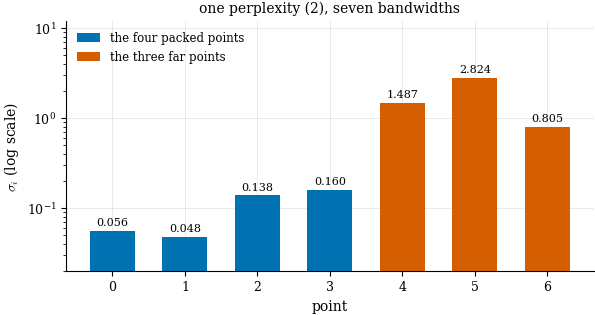

In [4]:
def cond_p(d2_row, sigma):
    "p_{j|i}: a Gaussian of width sigma around point i, normalized over the others"
    p = np.exp(-d2_row / (2 * sigma ** 2))
    return p / p.sum()


def perplexity_of(p):
    "Perp = 2^H, with H the Shannon entropy in bits"
    p = p[p > 0]
    return float(2.0 ** (-(p * np.log2(p)).sum()))


def sigma_for_perplexity(d2_row, target, lo=1e-6, hi=1e6, n_iter=80):
    "Perp grows monotonically with sigma, so bisect until it hits the target"
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        if perplexity_of(cond_p(d2_row, mid)) < target:
            lo = mid
        else:
            hi = mid
    return 0.5 * (lo + hi)


for k in (3, 5, 30):
    print(f"a fair {k:2d}-sided die (uniform over {k:2d} neighbors) has perplexity "
          f"{perplexity_of(np.full(k, 1 / k)):.6f}")

X_bs = np.array([[0.0, 0.0], [0.3, 0.1], [0.25, -0.2], [0.1, 0.35],
                 [5.0, 0.0], [7.5, 2.0], [-6.0, 4.0]])
D2_bs = ((X_bs[:, None, :] - X_bs[None, :, :]) ** 2).sum(-1)
TARGET_PERP = 2.0                             # <-- CHANGE ME (must stay below 6 here)

P_bs = np.zeros_like(D2_bs)
sig_bs = np.zeros(len(X_bs))
print(f"\ntarget perplexity {TARGET_PERP}   (points 0-3 are packed near the origin, 4-6 are far)")
for i in range(len(X_bs)):
    row = np.delete(D2_bs[i], i)
    sig_bs[i] = sigma_for_perplexity(row, TARGET_PERP)
    p_i = cond_p(row, sig_bs[i])
    P_bs[i, np.arange(len(X_bs)) != i] = p_i
    print(f"  point {i} at ({X_bs[i, 0]:5.2f},{X_bs[i, 1]:6.2f}): sigma = {sig_bs[i]:6.4f}"
          f"   perplexity = {perplexity_of(p_i):.6f}   largest p = {p_i.max():.3f}")

print(f"\nsigma is {sig_bs.max() / sig_bs.min():.0f}x larger for the loneliest point than for "
      "the tightest one: one knob, n bandwidths.")

try:      # sklearn's own binary search: a private helper, but it is THE one t-SNE calls
    from sklearn.manifold._utils import _binary_search_perplexity
    P_sk = _binary_search_perplexity(D2_bs.astype(np.float32), TARGET_PERP, 0)
    print(f"max |ours - sklearn's own binary search| = {np.abs(P_bs - P_sk).max():.1e}  "
          "(it works in float32 and stops at a tolerance)")
except Exception:                  # a private API: a future scikit-learn may move or rename it
    print("this scikit-learn does not expose _binary_search_perplexity -- check skipped")
print("every row is a probability distribution:", np.allclose(P_bs.sum(1), 1))

fig, ax = plt.subplots(figsize=(6.0, 3.2))
ax.bar(range(4), sig_bs[:4], color=C0, width=0.62, label="the four packed points")
ax.bar(range(4, 7), sig_bs[4:], color=C1, width=0.62, label="the three far points")
for i, v in enumerate(sig_bs):
    ax.text(i, v * 1.15, f"{v:.3f}", ha="center", fontsize=8)
ax.set_yscale("log"); ax.set_ylim(0.02, 12)
ax.set_xticks(range(7), [str(i) for i in range(7)])
ax.set_xlabel("point"); ax.set_ylabel(r"$\sigma_i$ (log scale)")
ax.set_title(f"one perplexity ({TARGET_PERP:g}), seven bandwidths", fontsize=10)
ax.legend(fontsize=8.5, loc="upper left")
plt.show()

Every perplexity is $2.000000$: the search hits the target exactly, and it does so with
$\sigma$ running from $0.0476$ for the point inside the tight knot to $2.8238$ for the lonely
one &mdash; a factor of **59**. Our conditional probabilities agree with scikit-learn's own binary
search to $8.5\times10^{-6}$ (it works in `float32` and stops at a tolerance, which is the whole
of the difference).

> &#128161; **This is the mechanism behind the first warning.** Because $\sigma_i$ stretches in
> sparse regions and shrinks in dense ones, a loose cluster and a tight cluster are handed to the
> optimizer as the *same* pattern of probabilities. The map cannot draw a difference it was never
> told about. We measure exactly that in &sect;6.

## 4. What perplexity actually controls

Perplexity sets how many neighbors each point pays attention to, so it is a dial between
**local** and **global**. There is no right value; the honest practice is to look at several.

Below: three genuinely separate clusters in 10-D, embedded at four perplexities and, at each
perplexity, with **three different seeds** &mdash; because a count taken from one run is not a
property of the method. Two numbers go with each picture: how many blobs a reader would count
(with **DBSCAN** &mdash; Session&nbsp;10b's first method, section&nbsp;1 there &mdash; standing in
for the eye) and what fraction of each point's true 10 nearest neighbors are still among its 10
nearest in the map.

"How many blobs a reader would count" needs a definition, and ours has two constants in it:
DBSCAN with `eps` $=$ **3.0** $\times$ the map's own median nearest-neighbor distance and
`min_samples` $=5$. That $3.0$ is a **choice**, so the cell ends by re-counting every map at
$2.0$, $3.0$, $4.0$ and $5.0$. Read that block before you believe any single integer.

perplexity  clumps (3 seeds)    10-NN kept: mean (range)


         2             28-29       0.391 (0.388 - 0.395)


         5             17-18       0.438 (0.434 - 0.443)


        30                 3       0.484 (0.480 - 0.489)


       100                 3       0.335 (0.332 - 0.338)


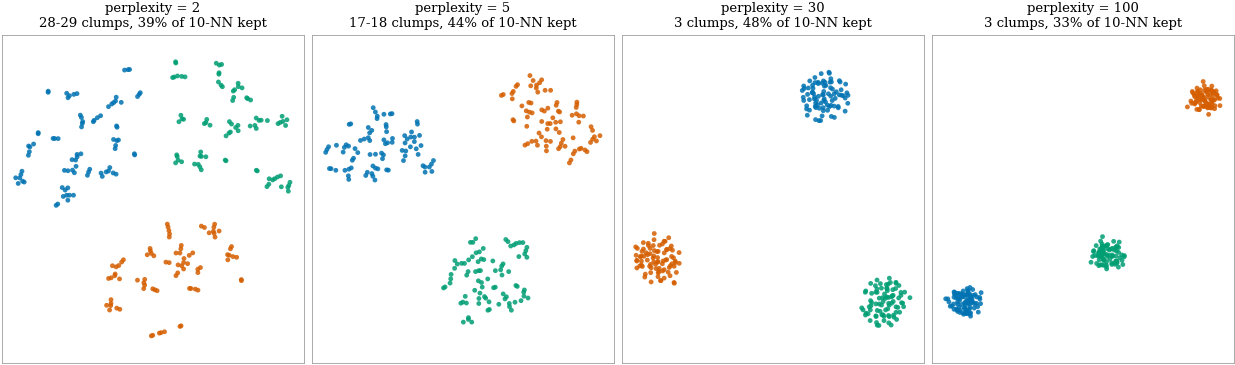

There are 3 real clusters. The panels are seed 0; the clump figure in each
title is the range over all three seeds. Color is the truth, the shapes t-SNE's opinion.

the clump count depends on the DBSCAN radius (we chose 3.0 x the map's median
nearest-neighbor distance). The same seed-0 maps, re-counted at four radii:
  radius factor     perp 2     perp 5    perp 30   perp 100
            2.0         13         17         14         13
            3.0         28         18          3          3


            4.0         24          4          3          3
            5.0         19          3          3          3


In [5]:
X_ps, y_ps = make_blobs(n_samples=250, centers=3, n_features=10, cluster_std=1.6, random_state=0)
base_ps = knn_sets(X_ps)
PERPS = (2, 5, 30, 100)                       # <-- CHANGE ME (each must stay below n = 250)
SEEDS_PS = (0, 1, 2)

maps_ps = {}
fig, axes = plt.subplots(1, len(PERPS), figsize=(12.4, 3.7))
print(f"{'perplexity':>10s} {'clumps (3 seeds)':>17s} {'10-NN kept: mean (range)':>27s}")
for ax, p in zip(axes, PERPS):
    cs, ks = [], []
    for s in SEEDS_PS:
        Z = TSNE(n_components=2, perplexity=p, init="random",
                 random_state=s).fit_transform(X_ps)
        cs.append(clumps(Z))
        ks.append(knn_overlap(base_ps, knn_sets(Z)))
        if s == SEEDS_PS[0]:
            maps_ps[p] = Z
    print(f"{p:10d} {span(cs):>17s} "
          f"{f'{np.mean(ks):.3f} ({min(ks):.3f} - {max(ks):.3f})':>27s}")
    scatter2d(ax, maps_ps[p], y_ps, f"perplexity = {p}\n{span(cs)} clumps, "
                                    f"{np.mean(ks):.0%} of 10-NN kept")
plt.show()
print(f"There are 3 real clusters. The panels are seed {SEEDS_PS[0]}; the clump figure in each")
print("title is the range over all three seeds. Color is the truth, the shapes t-SNE's opinion.\n")

print(f"the clump count depends on the DBSCAN radius (we chose {CLUMP_FACTOR} x the map's median")
print("nearest-neighbor distance). The same seed-0 maps, re-counted at four radii:")
print("  radius factor" + "".join(f"{f'perp {p}':>11s}" for p in PERPS))
for f in (2.0, 3.0, 4.0, 5.0):
    print(f"  {f:13.1f}" + "".join(f"{clumps(maps_ps[p], f):>11d}" for p in PERPS))

There are **3** clusters in that data. At perplexity 2 the map shows **28&ndash;29** of them across
the three seeds; at perplexity 5, **17&ndash;18**. Only from perplexity 30 does the count become
the truth, **3**, at every seed. Notice too that the neighbor-preservation column peaks at the
scikit-learn default (**0.484** at perplexity 30) and *falls again* at 100 (**0.335**): a very
large perplexity smears the local detail the method exists to show.

And even at its best, a t-SNE map keeps fewer than **half** of each point's true ten neighbors.
That is worth pausing on. The method we are about to trust with "who is near whom" gets the
neighbor list about half right &mdash; it is reliable about *groups*, not about individual points.

**Now read the radius block.** It says which of those integers you may quote.

* At factors $3.0$, $4.0$ and $5.0$ the perplexity-30 and perplexity-100 maps count **3, 3, 3**.
  That number is robust; the over-count at perplexity 2 (**28, 24, 19**) is robust in its
  *direction* too.
* At factor $2.0$ the radius is smaller than the gaps *inside* a real cluster, so it shreds
  everything: **14** clumps even at perplexity 30. That setting is not a stand-in for the eye, and
  it is why we did not choose it.
* The perplexity-5 count is the fragile one: **18, 4, 3** as the radius grows. So "17&ndash;18
  clumps at perplexity 5" is a statement about our detector as much as about t-SNE, and we will not
  put it in the recap.

> &#9888;&#65039; **So what does a clump mean at a small perplexity?** The next cell answers that
> in the harshest possible way: it runs the same sweep on data with **no structure at all**.

pure noise at perplexity   2: clumps over 3 seeds    21 | 10-NN kept 0.220


pure noise at perplexity   5: clumps over 3 seeds   4-7 | 10-NN kept 0.244


pure noise at perplexity  30: clumps over 3 seeds   1-4 | 10-NN kept 0.294


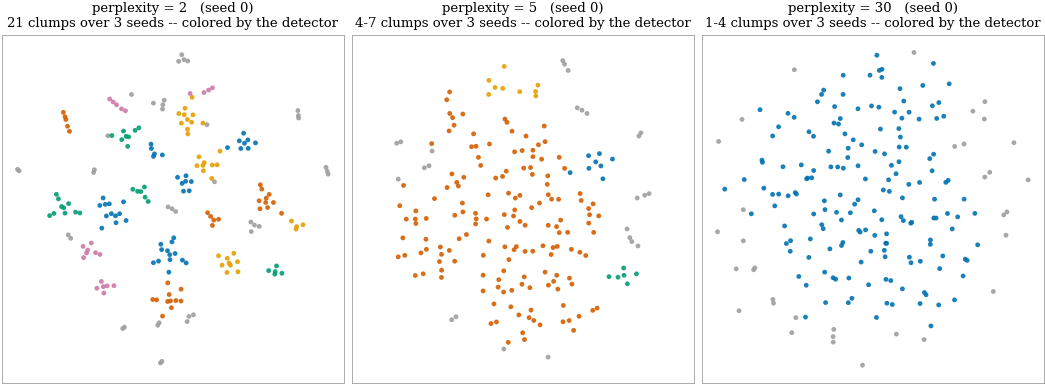


Color is DBSCAN's verdict on the seed-0 map (gray = its noise label), so the left
panel's confetti IS the count. There is nothing in this data: every clump was manufactured.


In [6]:

rng_nz = np.random.default_rng(3)
noise_nz = rng_nz.normal(size=(200, 50))      # 200 points, 50-D, NO structure whatsoever
base_nz = knn_sets(noise_nz)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.9))
for ax, p in zip(axes, (2, 5, 30)):
    cs, ks, first = [], [], None
    for s in (0, 1, 2):
        Z = TSNE(n_components=2, perplexity=p, init="random",
                 random_state=s).fit_transform(noise_nz)
        cs.append(clumps(Z))
        ks.append(knn_overlap(base_nz, knn_sets(Z)))
        first = Z if first is None else first
    print(f"pure noise at perplexity {p:3d}: clumps over 3 seeds {span(cs):>5s}"
          f" | 10-NN kept {np.mean(ks):.3f}")
    lab = clump_labels(first)                 # color by what the detector actually found
    scatter_clumps(ax, first, lab, f"perplexity = {p}   (seed 0)\n"
                                   f"{span(cs)} clumps over 3 seeds -- colored by the detector")
plt.show()
print("\nColor is DBSCAN's verdict on the seed-0 map (gray = its noise label), so the left")
print("panel's confetti IS the count. There is nothing in this data: every clump was manufactured.")

**21 clusters in a dataset that has none.** Put the two experiments side by side: at perplexity
2, data with three real clusters draws 28&ndash;29 clumps and data with *zero* real clusters draws
**21** at every seed. From the picture alone you cannot tell those two situations apart. (This is
the classic demonstration from Wattenberg, Vi&eacute;gas &amp; Johnson, *How to Use t-SNE
Effectively*, Distill 2016, which Lecture&nbsp;11 reproduces.)

At perplexity 30 the noise is *usually* drawn as the single structureless blob it is &mdash; but
not always: across the three seeds the count is **1&ndash;4**. That is the sharpest possible
argument for the rule, and it is why the rule has two halves:

> **Rule.** A clump is worth believing only if it survives several perplexities **and** several
> seeds. One run at one setting is not evidence of anything.

Notice also the neighbor column: on pure noise t-SNE keeps only **0.220&ndash;0.294** of each
point's true neighbors, against **0.335&ndash;0.484** on real clusters. Low neighbor preservation
is a hint that there was little local structure to preserve &mdash; but it is a weak one, and it is
not visible in the picture at all.

## 5. Why the map kernel is a Student-$t$: the crowding problem

In the map, similarity is **not** Gaussian. t-SNE uses a Student-$t$ with one degree of freedom
(a Cauchy),

$$q_{ij}\;\propto\;\big(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2\big)^{-1},$$

whose tail falls off like $d^{-2}$ instead of $e^{-d^2}$. The reason is **crowding**: a
high-dimensional neighborhood has vastly more room than a 2-D one, so the moderately-distant
points cannot all fit at their proper distances and get crushed toward the center.

Two measurements make that concrete. First, the room that is missing: in $m$ dimensions you can
place $m+1$ **mutually equidistant** points (a regular simplex), and we flatten the 10-D one to
2-D as well as it can possibly be flattened. Second, the room the heavy tail buys: the distance
at which each kernel decays to a given similarity.

"As well as it can possibly be flattened" needs a method, and the honest one is
**multidimensional scaling (MDS)** &mdash; the oldest member of this family, and the only place
this notebook uses it. Hand it a matrix of distances and it places points in the plane so as to
minimize the squared mismatch between the distances it *draws* and the distances it was *given*.
No neighbor graph, no probabilities, no kernel: just the distances, fitted as well as least
squares can fit them. If even MDS cannot keep 55 equal edges equal, nothing can. (`MDS` comes
back in &sect;7 for a different reason: like `TSNE`, it has no `.transform`.)

in  2-D you can place  3 mutually equidistant points: all   3 distances between 1.000 and 1.000
in  3-D you can place  4 mutually equidistant points: all   6 distances between 1.000 and 1.000
in 10-D you can place 11 mutually equidistant points: all  55 distances between 1.000 and 1.000

the best 2-D arrangement of those 11 points: distances 0.407 to 1.335 -- a 3.28x spread where the truth is 1.00x
of the 55 edges, 30 are drawn shorter than the average and 25 longer;
the worst is off by 54%.
that unavoidable stretch is the crowding problem.

similarity q  Gaussian needs d  Student-t needs d    room
       0.500             0.833              1.000   1.20x
       0.100             1.517              3.000   1.98x
       0.010             2.146              9.950   4.64x
       0.001             2.628             31.607  12.03x


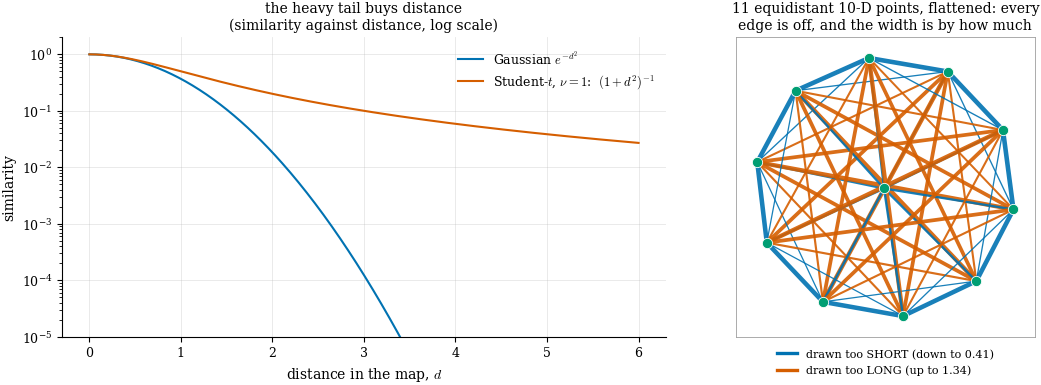

In [7]:

def simplex(m):
    "m+1 mutually equidistant points in m dimensions, scaled to unit mean distance"
    V = np.eye(m + 1) - 1 / (m + 1)
    U, s, _ = np.linalg.svd(V, full_matrices=False)
    Pt = U[:, :m] * s[:m]
    return Pt / pdist(Pt).mean()


for m in (2, 3, 10):
    d = pdist(simplex(m))
    print(f"in {m:2d}-D you can place {m + 1:2d} mutually equidistant points: "
          f"all {len(d):3d} distances between {d.min():.3f} and {d.max():.3f}")

S_cr = simplex(10)
D_cr = np.sqrt(((S_cr[:, None] - S_cr[None, :]) ** 2).sum(-1))
Z_cr = MDS(n_components=2, metric="precomputed", init="random", random_state=0,
           n_init=8, normalized_stress=False).fit_transform(D_cr)
d_cr = pdist(Z_cr)
print(f"\nthe best 2-D arrangement of those 11 points: distances {d_cr.min():.3f} to "
      f"{d_cr.max():.3f} -- a {d_cr.max() / d_cr.min():.2f}x spread where the truth is 1.00x")
print(f"of the {len(d_cr)} edges, {int((d_cr < d_cr.mean()).sum())} are drawn shorter than the "
      f"average and {int((d_cr >= d_cr.mean()).sum())} longer;")
print(f"the worst is off by {100 * np.abs(d_cr / d_cr.mean() - 1).max():.0f}%.")
print("that unavoidable stretch is the crowding problem.\n")

print(f"{'similarity q':>12s} {'Gaussian needs d':>17s} {'Student-t needs d':>18s} {'room':>7s}")
for q in (0.5, 0.1, 0.01, 0.001):
    dg, dt = np.sqrt(-np.log(q)), np.sqrt(1 / q - 1)
    print(f"{q:12.3f} {dg:17.3f} {dt:18.3f} {dt / dg:6.2f}x")

r_cr = np.linspace(0, 6, 400)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 3.9), width_ratios=[1.45, 1.0])
a1.plot(r_cr, np.exp(-r_cr ** 2), color=C0, label="Gaussian $e^{-d^2}$")
a1.plot(r_cr, 1 / (1 + r_cr ** 2), color=C1,
        label="Student-$t$, $\\nu=1$:  $(1+d^2)^{-1}$")
a1.set_yscale("log"); a1.set_ylim(1e-5, 2)
a1.set_xlabel("distance in the map, $d$"); a1.set_ylabel("similarity")
a1.legend(fontsize=9)
a1.set_title("the heavy tail buys distance\n(similarity against distance, log scale)",
             fontsize=10)

iu, ju = np.triu_indices(len(Z_cr), 1)                 # the same order pdist uses
err_cr = d_cr / d_cr.mean() - 1.0                      # each edge's relative length error
a2.add_collection(LineCollection(
    np.stack([Z_cr[iu], Z_cr[ju]], axis=1),
    colors=[C0 if e < 0 else C1 for e in err_cr],
    linewidths=0.3 + 3.0 * np.abs(err_cr) / np.abs(err_cr).max(), alpha=0.9, zorder=1))
a2.scatter(Z_cr[:, 0], Z_cr[:, 1], s=55, color=CG, zorder=3, edgecolor="white", linewidth=0.6)
bare(a2); focus(a2, Z_cr, q=0.0, pad=0.16)
a2.legend(handles=[Line2D([], [], color=C0, lw=2.4,
                          label=f"drawn too SHORT (down to {d_cr.min():.2f})"),
                   Line2D([], [], color=C1, lw=2.4,
                          label=f"drawn too LONG (up to {d_cr.max():.2f})")],
          fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.015), ncol=1,
          frameon=False, borderpad=0.2, handlelength=1.8)   # BELOW the panel: all 11 nodes show
a2.set_title("11 equidistant 10-D points, flattened: every\nedge is off, and the width is by "
             "how much", fontsize=10)
plt.show()

Eleven points that are *all exactly one unit apart* in 10-D cannot be laid out in the plane any
better than a **3.28&times;** spread between the shortest and longest edge. The plane simply does
not have the room, and no optimizer can conjure it.

The Student-$t$ tail is how t-SNE copes. To express a similarity of $0.01$, a Gaussian kernel
insists the pair sit $2.15$ apart; the Student-$t$ lets them sit $9.95$ apart &mdash; **4.64&times;**
further. That extra space is handed to exactly the moderately-distant pairs that crowding was
squeezing. It is also why **distances in a t-SNE map are not distances**: the kernel was chosen
to distort them.

## 6. The warning that actually misleads people

Everyone repeats "cluster sizes are meaningless in a t-SNE plot". Far fewer people know the
second half, which is the one that changes conclusions: **the gaps between clusters are
meaningless too**.

Lecture&nbsp;11's experiment, reproduced here. Three clusters in 20 dimensions, built so that

* their radii are in the ratio $1:5:25$, and
* the gap between clusters 2 and 3 is **5&times;** the gap between clusters 1 and 2.

Everything about the answer is known in advance. Then we embed &mdash; with **both** initializations,
so that "it is not an artifact of the PCA init" is measured rather than asserted &mdash; and read
both ratios off the map.

                                            cluster radii  size ratio    the two gaps  gap ratio
in the 20-D data                       [4.5, 22.5, 110.5]      24.83x       [60, 302]      5.00x
in the map, init="pca", seed 0            [5.1, 5.0, 5.1]       1.00x        [39, 38]      0.99x
in the map, init="random", seed 0         [4.6, 4.6, 4.6]       1.00x        [39, 40]      1.01x

the data was built with a 24.8x size ratio and a 5.0x gap ratio. Over 3 t-SNE seeds per initialization the map reports:
  init="pca"      size ratio 0.995x +/- 0.000   gap ratio 0.987x +/- 0.000   runs [0.995, 0.995, 0.995] and [0.987, 0.987, 0.987]
  init="random"   size ratio 0.998x +/- 0.002   gap ratio 0.970x +/- 0.046   runs [0.996, 0.999, 1.0] and [1.013, 0.922, 0.976]

(init="pca" is deterministic -- the seed only picks the RANDOM start -- so its three
runs are one run, and its spread is 0 by construction. The init="random" spread is the
real one. Exercise 5 turns that into a question.)


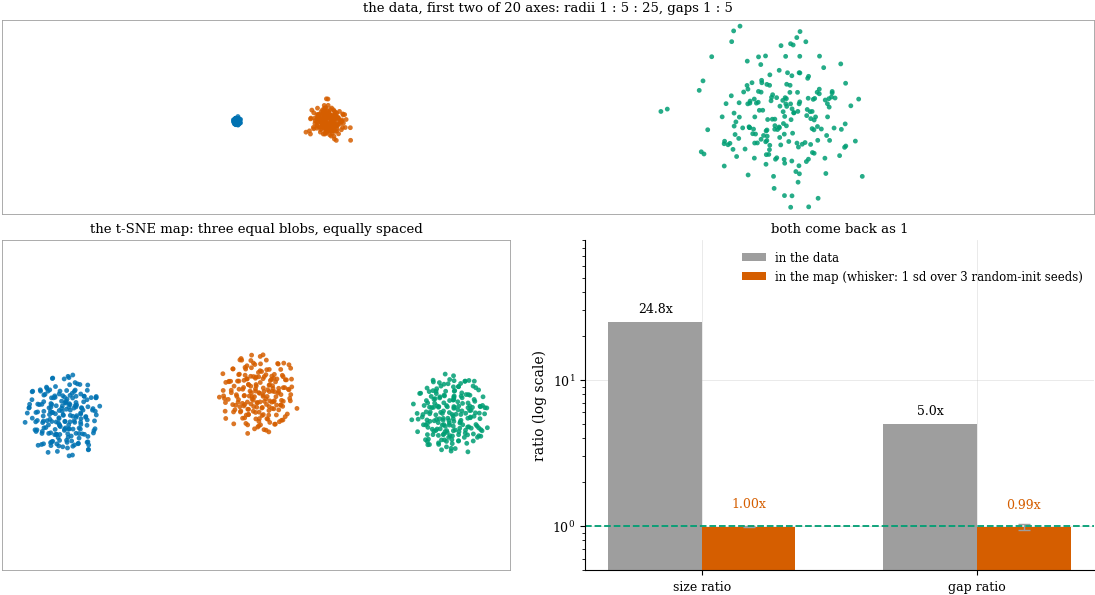

In [8]:

X_ug, y_ug = make_uneven_clusters(n_per=200, d=20, radii=(1.0, 5.0, 25.0),
                                  gaps=(60.0, 300.0), seed=0)
INITS = ("pca", "random")                     # <-- CHANGE ME (both are measured below)
SEEDS_UG = (0, 1, 2)                          # <-- CHANGE ME (t-SNE seeds per initialization)


def rms_radius(P):
    "root-mean-square distance from a cluster's own center"
    return float(np.sqrt(((P - P.mean(0)) ** 2).sum(1).mean()))


def size_and_gap(P, lab):
    "the three radii, the two center-to-center gaps, and the two ratios"
    rad = [rms_radius(P[lab == k]) for k in (0, 1, 2)]
    cen = [P[lab == k].mean(0) for k in (0, 1, 2)]
    g01 = float(np.linalg.norm(cen[1] - cen[0]))
    g12 = float(np.linalg.norm(cen[2] - cen[1]))
    return rad, g01, g12, rad[2] / rad[0], g12 / g01


maps_ug, rat_ug = {}, {}
for ini in INITS:
    rs, rg = [], []
    for s in SEEDS_UG:
        Z = TSNE(n_components=2, perplexity=30, init=ini, random_state=s).fit_transform(X_ug)
        _, _, _, a, b = size_and_gap(Z, y_ug)
        rs.append(a); rg.append(b)
        if s == SEEDS_UG[0]:
            maps_ug[ini] = Z
    rat_ug[ini] = (np.array(rs), np.array(rg))

rows_ug = {"in the 20-D data": size_and_gap(X_ug, y_ug)}
for ini in INITS:
    rows_ug[f'in the map, init="{ini}", seed {SEEDS_UG[0]}'] = size_and_gap(maps_ug[ini], y_ug)

print(f"{'':34s} {'cluster radii':>22s} {'size ratio':>11s} {'the two gaps':>15s} "
      f"{'gap ratio':>10s}")
for nm, (rad, g01, g12, rs_, rg_) in rows_ug.items():
    print(f"{nm:34s} {str([round(v, 1) for v in rad]):>22s} {rs_:10.2f}x "
          f"{str([round(g01), round(g12)]):>15s} {rg_:9.2f}x")

rs_d, rg_d = rows_ug["in the 20-D data"][3], rows_ug["in the 20-D data"][4]
print(f"\nthe data was built with a {rs_d:.1f}x size ratio and a {rg_d:.1f}x gap ratio. Over "
      f"{len(SEEDS_UG)} t-SNE seeds per initialization the map reports:")
for ini in INITS:
    rs_, rg_ = rat_ug[ini]
    print(f'  init="{ini}"{"":{8 - len(ini)}s} size ratio {rs_.mean():.3f}x +/- '
          f'{rs_.std(ddof=1):.3f}   gap ratio {rg_.mean():.3f}x +/- {rg_.std(ddof=1):.3f}   '
          f'runs {np.round(rs_, 3).tolist()} and {np.round(rg_, 3).tolist()}')
print(f'\n(init="pca" is deterministic -- the seed only picks the RANDOM start -- so its three')
print(f'runs are one run, and its spread is 0 by construction. The init="random" spread is the')
print(f'real one. Exercise 5 turns that into a question.)')

fig = plt.figure(figsize=(11.0, 6.0))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.7])
ax_d, ax_m, ax_b = fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
scatter2d(ax_d, X_ug[:, :2], y_ug,
          "the data, first two of 20 axes: radii 1 : 5 : 25, gaps 1 : 5")
scatter2d(ax_m, maps_ug["pca"], y_ug, "the t-SNE map: three equal blobs, equally spaced")
rs_m, rg_m = rat_ug["pca"][0].mean(), rat_ug["pca"][1].mean()
rs_e, rg_e = rat_ug["random"][0].std(ddof=1), rat_ug["random"][1].std(ddof=1)
xs, w = np.arange(2), 0.34
ax_b.bar(xs - w / 2, [rs_d, rg_d], w, color=CX, label="in the data")
ax_b.bar(xs + w / 2, [rs_m, rg_m], w, color=C1, yerr=[rs_e, rg_e], capsize=4,
         error_kw=dict(ecolor=CX, lw=1.0),
         label=f'in the map (whisker: 1 sd over {len(SEEDS_UG)} random-init seeds)')
for i, (aa, bb) in enumerate(((rs_d, rs_m), (rg_d, rg_m))):
    ax_b.text(i - w / 2, aa * 1.16, f"{aa:.1f}x", ha="center", fontsize=9)
    ax_b.text(i + w / 2, bb * 1.35, f"{bb:.2f}x", ha="center", fontsize=9, color=C1)
ax_b.axhline(1.0, color=CG, ls="--", lw=1.3)
ax_b.set_yscale("log"); ax_b.set_ylim(0.5, 90); ax_b.set_xticks(xs)
ax_b.set_xticklabels(["size ratio", "gap ratio"])
ax_b.set_ylabel("ratio (log scale)"); ax_b.legend(fontsize=8.5, loc="upper right")
ax_b.set_title("both come back as 1", fontsize=9.5)
plt.show()

Both ratios come back as **1**, on every run. A $24.8\times$ difference in cluster size is drawn
as **$0.995\times$** and a $5.0\times$ difference in separation as **$0.987\times$** &mdash;
rounded to two decimals, exactly the numbers on Lecture&nbsp;11's slide. The `init="random"` rows
are there so the obvious objection is answered by measurement and not by assertion: over three
seeds they give **$0.998\times\pm0.002$** and **$0.970\times\pm0.046$**. It is not an artifact
of the PCA initialization &mdash; it is what the method does.

> &#9888;&#65039; **Why the `init="pca"` spread is exactly $0.000$.** That initialization is
> deterministic, so the "three seeds" there are one run printed three times; the seed only chooses
> a *random* start. The `init="random"` column is the real measurement of run-to-run spread, and
> exercise&nbsp;5 turns the observation into a question.

> &#11088; **Why.** The $\sigma_i$ search equalizes densities (that is &sect;3's factor of 59), so
> sizes go. And the KL divergence $\sum p_{ij}\log(p_{ij}/q_{ij})$ charges heavily for pulling
> true neighbors apart but almost nothing for placing distant pairs close together &mdash; so once
> two clusters are separate, how far apart they are drawn is free, and the layout settles wherever
> the repulsion happens to balance.

## 7. The same data, a different picture &mdash; and no map for new points

t-SNE is a **stochastic optimizer with no model**. Two consequences that bite in practice:

1. Run it again with another seed and you get another picture. What is stable is the
   *partition*, not the coordinates &mdash; and, it turns out, not even exactly who your ten
   nearest neighbors are.
2. There is **no** `transform`. `TSNE` cannot place a new point in an existing map at all: you
   must refit &mdash; and refitting moves the old points too.

We measure the first with the **Procrustes disparity** (scale, rotation and reflection removed;
$0$ means the same picture, $1$ means unrelated) and with neighbor overlap, and the second by
adding twenty points and refitting.

each run, against the truth and against the data:
  seed 0: k-means on the map recovers the 4 classes, ARI 1.000 | only 50% of a point's true 10 neighbors are its 10 neighbors here
  seed 1: k-means on the map recovers the 4 classes, ARI 1.000 | only 50% of a point's true 10 neighbors are its 10 neighbors here
  seed 2: k-means on the map recovers the 4 classes, ARI 1.000 | only 51% of a point's true 10 neighbors are its 10 neighbors here

the runs against each other:
  seeds 0 vs 1: Procrustes disparity 0.694 (0 = the same picture) | shared 10-NN 64%
  seeds 0 vs 2: Procrustes disparity 0.745 (0 = the same picture) | shared 10-NN 58%
  seeds 1 vs 2: Procrustes disparity 0.763 (0 = the same picture) | shared 10-NN 62%

which of these can place a NEW point into an existing map?
  TSNE                     has .transform: False
  MDS                      has .transform: False
  SpectralEmbedding        has .transform: False
  Isomap                   has .transform: True
  LocallyLinearEm

add 20 points and refit: the OLD points move too -- Procrustes disparity 0.133, shared 10-NN 60%


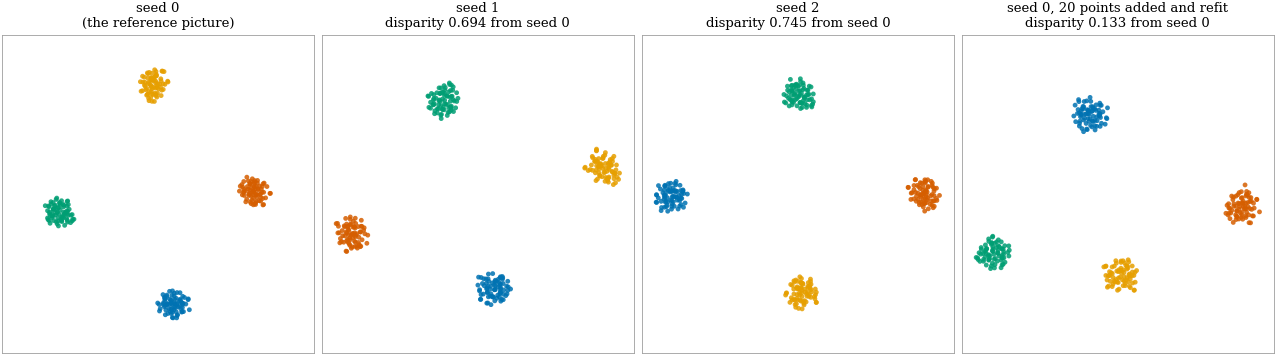

In [9]:

X_sd, y_sd = make_blobs(n_samples=300, centers=4, n_features=10, cluster_std=1.6, random_state=0)
base_sd = knn_sets(X_sd)
runs_sd = [TSNE(n_components=2, perplexity=30, init="random",
                random_state=s).fit_transform(X_sd) for s in (0, 1, 2)]

print("each run, against the truth and against the data:")
for s, Z in zip((0, 1, 2), runs_sd):
    ari = adjusted_rand_score(y_sd, KMeans(4, n_init=10, random_state=0).fit_predict(Z))
    print(f"  seed {s}: k-means on the map recovers the 4 classes, ARI {ari:.3f} | only "
          f"{knn_overlap(base_sd, knn_sets(Z)):.0%} of a point's true 10 neighbors are its 10 "
          "neighbors here")
print("\nthe runs against each other:")
disp_sd = {}
for i in range(3):
    for j in range(i + 1, 3):
        disp_sd[(i, j)] = float(procrustes(runs_sd[i], runs_sd[j])[2])
        print(f"  seeds {i} vs {j}: Procrustes disparity "
              f"{disp_sd[(i, j)]:.3f} (0 = the same picture) | shared "
              f"10-NN {knn_overlap(knn_sets(runs_sd[i]), knn_sets(runs_sd[j])):.0%}")

print("\nwhich of these can place a NEW point into an existing map?")
for cls in (TSNE, MDS, SpectralEmbedding, Isomap, LocallyLinearEmbedding):
    print(f"  {cls.__name__:24s} has .transform: {hasattr(cls, 'transform')}")
rng_sd = np.random.default_rng(7)
X_plus = np.vstack([X_sd, X_sd[:20] + rng_sd.normal(0, 0.05, (20, 10))])   # 20 near-duplicates
Z_plus = TSNE(n_components=2, perplexity=30, init="random",
              random_state=0).fit_transform(X_plus)
disp_plus = float(procrustes(runs_sd[0], Z_plus[:len(X_sd)])[2])
print(f"add 20 points and refit: the OLD points move too -- Procrustes disparity "
      f"{disp_plus:.3f}, shared 10-NN "
      f"{knn_overlap(knn_sets(runs_sd[0]), knn_sets(Z_plus[:len(X_sd)])):.0%}")

fig, axes = plt.subplots(1, 4, figsize=(12.8, 3.6))
titles_sd = ["seed 0\n(the reference picture)",
             f"seed 1\ndisparity {disp_sd[(0, 1)]:.3f} from seed 0",
             f"seed 2\ndisparity {disp_sd[(0, 2)]:.3f} from seed 0",
             f"seed 0, 20 points added and refit\ndisparity {disp_plus:.3f} from seed 0"]
for ax, Z, ttl in zip(axes, runs_sd + [Z_plus[:len(X_sd)]], titles_sd):
    scatter2d(ax, Z, y_sd, ttl)
plt.show()

Every seed recovers the four classes perfectly (**ARI 1.000**) while producing a visibly
different picture (**disparity 0.694 to 0.763**, after scale, rotation and reflection have been
removed). Even the neighbor lists only agree about **58&ndash;64%** of the time between two runs of
the same method on the same data.

So: the **partition** is a finding; the **layout** is not. Never compare two t-SNE maps
point-by-point, and never quote a coordinate.

Adding twenty near-duplicate points and refitting moves the original 300 as well (disparity
$0.133$, **60%** shared neighbors). And the `.transform` table is not an accident of the library:
`TSNE`, `MDS` and `SpectralEmbedding` all answer **False**, because each of them optimizes
coordinates directly and has no function to apply to a new point; `Isomap` and
`LocallyLinearEmbedding` answer **True**, because each fits an explicit map. The real `umap-learn`
package provides a `transform` too, and that is one of the few clear-cut differences between
t-SNE and UMAP.

## 8. UMAP: build a graph, then draw it

UMAP reaches a similar picture by different bookkeeping, in **two separable steps**:

**Step 1 &mdash; the graph.** For each point, with $\rho_i$ the distance to its *nearest* neighbor,

$$p_{j\mid i}=\exp\!\left(-\frac{\max(0,\;d_{ij}-\rho_i)}{\sigma_i}\right),$$

with $\sigma_i$ found by **binary search** so that $\sum_j p_{j\mid i}=\log_2 k$ &mdash; the very
same trick as &sect;3, aimed at a different target. Subtracting $\rho_i$ gives every point one
membership of exactly $1$, so the graph is never disconnected. The two directions are then
combined by the probabilistic t-conorm $p_{ij}=p_{j\mid i}+p_{i\mid j}-p_{j\mid i}p_{i\mid j}$.

**Step 2 &mdash; the layout.** Fit a smooth curve $1/(1+a\,r^{2b})$ to the shape `min_dist` asks
for, then run SGD in which sampled **edges attract** and random **non-edges repel**.

`umap-learn` is not installed here, so the next cell *is* UMAP: about fifty lines. The test that
it is the real thing is the $(a,b)$ it fits for `min_dist = 0.1`.

memberships sum to 3.906891 +/- 6e-06 for every point; log2(15) = 3.906891
sigma runs from 0.059 to 1.627, a 27x range -- the same density adjustment t-SNE makes
P is symmetric: True; largest membership 1.000 (rho_i guarantees a 1); mean degree 20.5

fit_ab(min_dist=0.1) -> a = 1.5769, b = 0.8951    (umap-learn publishes a = 1.577, b = 0.895)

the layout is stochastic too, so run it three times:


  layout seed 0: ARI 1.000 | cluster spreads [1.11, 1.13, 1.12] -> a 1.02x range


  layout seed 1: ARI 1.000 | cluster spreads [1.12, 1.1, 1.09] -> a 1.03x range


  layout seed 2: ARI 1.000 | cluster spreads [1.14, 1.14, 1.05] -> a 1.09x range
  in the DATA the same three spreads are [1.18, 3.31, 1.11] -> a 2.98x range   <-- the SAME warning as t-SNE


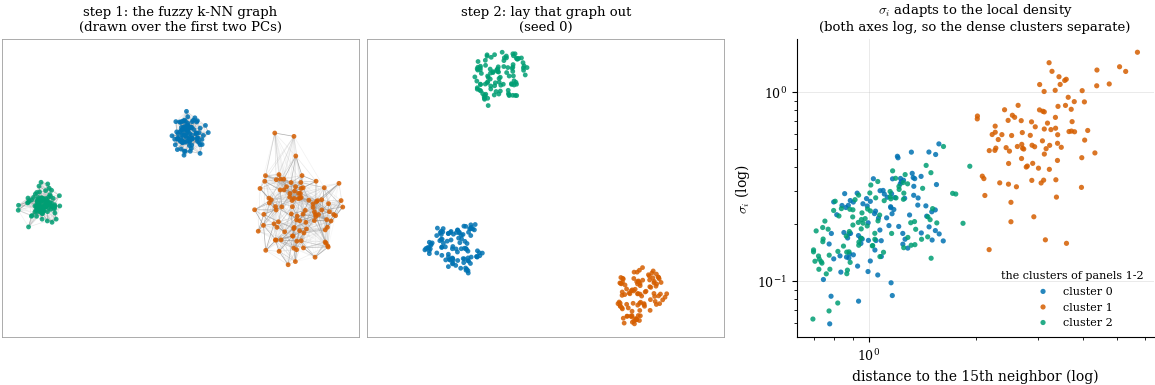

In [10]:
def fuzzy_graph(X, n_neighbors=15):
    "UMAP step 1: the fuzzy k-NN graph"
    # rho_i is the distance to the NEAREST neighbor, so every point keeps one membership of
    # exactly 1 and the graph can never be disconnected; sigma_i is found by binary search so
    # the memberships sum to log2(k); then a + b - ab symmetrizes the two directions.
    dist, idx = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(X).kneighbors(X)
    dist, idx = dist[:, 1:], idx[:, 1:]                       # drop self
    n, target = len(X), np.log2(n_neighbors)
    rho, sigma = dist[:, 0].copy(), np.ones(n)
    for i in range(n):
        lo, hi, mid = 0.0, np.inf, 1.0
        for _ in range(64):
            s = np.exp(-np.maximum(dist[i] - rho[i], 0) / mid).sum()
            if abs(s - target) < 1e-5:
                break
            if s > target:
                hi, mid = mid, (lo + mid) / 2
            else:
                lo, mid = mid, mid * 2 if hi == np.inf else (mid + hi) / 2
        sigma[i] = mid
    P = np.zeros((n, n))
    P[np.repeat(np.arange(n), idx.shape[1]), idx.ravel()] = np.exp(
        -np.maximum(dist - rho[:, None], 0) / sigma[:, None]).ravel()
    return P + P.T - P * P.T, rho, sigma, dist


def fit_ab(min_dist=0.1, spread=1.0):
    "UMAP step 2a: fit 1/(1 + a r^(2b)) to the curve min_dist asks for"
    # This is the ONLY place min_dist enters: it shapes the layout's target curve and never
    # touches the graph built above.
    r = np.linspace(0, 3 * spread, 300)
    target = np.where(r < min_dist, 1.0, np.exp(-(r - min_dist) / spread))
    (a, b), _ = curve_fit(lambda r, a, b: 1 / (1 + a * r ** (2 * b)), r, target,
                          p0=[1, 1], maxfev=20000)
    return float(a), float(b)


def umap_layout(P, n_epochs=300, a=1.5769, b=0.8951, seed=0, n_neg=5, lr0=1.0):
    "UMAP step 2b. Sampled edges attract, random non-edges repel, the rate decays to 0."
    n = len(P)
    rng = np.random.default_rng(seed)
    Y = rng.normal(scale=10.0, size=(n, 2))
    rows, cols = np.nonzero(np.triu(P, 1))
    w = P[rows, cols] / P[rows, cols].max()
    for ep in range(n_epochs):
        lr = lr0 * (1 - ep / n_epochs)
        m = rng.random(len(rows)) < w                         # sample edges by membership
        i, j = rows[m], cols[m]
        d = Y[i] - Y[j]
        r2 = np.einsum("ij,ij->i", d, d) + 1e-12
        co = (-2 * a * b * r2 ** (b - 1)) / (1 + a * r2 ** b)              # attraction
        g = np.clip(co[:, None] * d, -4, 4) * lr
        np.add.at(Y, i, g); np.add.at(Y, j, -g)
        src = np.repeat(i, n_neg)
        dst = rng.integers(0, n, len(src))
        ok = src != dst
        src, dst = src[ok], dst[ok]
        dn = Y[src] - Y[dst]
        r2n = np.einsum("ij,ij->i", dn, dn) + 1e-12
        cn = (2 * b) / ((1e-3 + r2n) * (1 + a * r2n ** b))                 # repulsion
        np.add.at(Y, src, np.clip(cn[:, None] * dn, -4, 4) * lr)
    return Y


X_um, y_um = make_blobs(n_samples=300, centers=3, cluster_std=[0.6, 1.8, 0.6],
                        n_features=4, random_state=3)
P_um, rho_um, sigma_um, dist_um = fuzzy_graph(X_um, n_neighbors=15)
sums_um = np.array([np.exp(-np.maximum(dist_um[i] - rho_um[i], 0) / sigma_um[i]).sum()
                    for i in range(len(X_um))])
print(f"memberships sum to {sums_um.mean():.6f} +/- {sums_um.std():.0e} for every point; "
      f"log2(15) = {np.log2(15):.6f}")
print(f"sigma runs from {sigma_um.min():.3f} to {sigma_um.max():.3f}, a "
      f"{sigma_um.max() / sigma_um.min():.0f}x range -- the same density adjustment t-SNE makes")
print(f"P is symmetric: {np.allclose(P_um, P_um.T)}; largest membership {P_um.max():.3f} "
      f"(rho_i guarantees a 1); mean degree {float((P_um > 0).sum(1).mean()):.1f}")

a_um, b_um = fit_ab(0.1)
print(f"\nfit_ab(min_dist=0.1) -> a = {a_um:.4f}, b = {b_um:.4f}    "
      "(umap-learn publishes a = 1.577, b = 0.895)")

print("\nthe layout is stochastic too, so run it three times:")
sd_um = spreads(X_um, y_um)
for s in (0, 1, 2):
    Ys = umap_layout(P_um, n_epochs=300, a=a_um, b=b_um, seed=s)
    sm = spreads(Ys, y_um)
    print(f"  layout seed {s}: ARI "
          f"{adjusted_rand_score(y_um, KMeans(3, n_init=10, random_state=0).fit_predict(Ys)):.3f}"
          f" | cluster spreads {[round(v, 2) for v in sm]} -> a {max(sm) / min(sm):.2f}x range")
    if s == 0:
        Y_um = Ys
print(f"  in the DATA the same three spreads are {[round(v, 2) for v in sd_um]} -> a "
      f"{max(sd_um) / min(sd_um):.2f}x range   <-- the SAME warning as t-SNE")

V_um = PCA(n_components=2).fit_transform(X_um)
rows_um, cols_um = np.nonzero(np.triu(P_um, 1))
edge_rgba = np.zeros((len(rows_um), 4))
edge_rgba[:, :3] = float(CX)                                  # gray edges ...
edge_rgba[:, 3] = 0.85 * P_um[rows_um, cols_um]               # ... faded by membership strength

fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.9))
axes[0].add_collection(LineCollection(
    np.stack([V_um[rows_um], V_um[cols_um]], axis=1), colors=edge_rgba, linewidths=0.5, zorder=1))
scatter2d(axes[0], V_um, y_um, "step 1: the fuzzy k-NN graph\n(drawn over the first two PCs)")
scatter2d(axes[1], Y_um, y_um, "step 2: lay that graph out\n(seed 0)")
for k in sorted(np.unique(y_um)):
    m = y_um == k
    axes[2].scatter(dist_um[m, 14], sigma_um[m], s=14, color=CLUSTER_COLORS[int(k)],
                    alpha=0.85, edgecolor="none", label=f"cluster {k}")
axes[2].set_xscale("log"); axes[2].set_yscale("log")     # the two tight clusters pile up linearly
axes[2].set_xlabel("distance to the 15th neighbor (log)")
axes[2].set_ylabel(r"$\sigma_i$ (log)")
axes[2].legend(fontsize=8, loc="lower right", title="the clusters of panels 1-2",
               title_fontsize=8)
axes[2].set_title(r"$\sigma_i$ adapts to the local density" "\n(both axes log, so the dense "
                  "clusters separate)", fontsize=9.5)
plt.show()

Three things were just checked, not asserted.

1. **The calibration works.** Every point's memberships sum to $3.906891\pm6\times10^{-6}$,
   against the target $\log_2 15 = 3.906891$ &mdash; and the $\sigma_i$ that achieve it range over
   a factor of **27**, from $0.059$ to $1.627$. The third panel shows why: $\sigma_i$ rises with
   the distance to the 15th neighbor, close to proportionally &mdash; the panel puts both on log
   axes so that the two tight clusters do not pile into one corner &mdash; and that is exactly
   what "adapt to the local density" means.
2. **It is the real algorithm.** The fitted curve gives $a = 1.5769$, $b = 0.8951$; `umap-learn`
   publishes $1.577$ and $0.895$. Fifty lines of NumPy reproduce the package's own constants to
   four decimals.
3. **The same warning applies.** Three blobs whose spreads differ by **2.98&times;** in the data
   come out between **1.02&times;** and **1.09&times;** apart in the map, over three layout seeds,
   while the partition is recovered perfectly (**ARI 1.000**) every time. It is the *same* cause as
   in t-SNE: the per-point bandwidth search that makes a dense region and a sparse region
   comparable is precisely what erases the difference between them.

## 9. The two knobs, and which one can change your conclusions

UMAP's separation into a graph step and a layout step means its two main knobs act in different
places:

* **`n_neighbors`** rebuilds the **graph**. It decides what counts as "nearby", so it decides
  what the algorithm is being asked to preserve. It can genuinely change the answer.
* **`min_dist`** enters **only** through $(a,b)$ &mdash; the layout's target curve. It cannot reveal
  or destroy structure; it can only make the same structure look tighter or looser.

The bottom row of the next figure uses the **same graph `P_um`** for all three panels, so anything
that changes there is presentation, not evidence. The ARI column is the check: it is printed for
both rows, and only the top row can move it.

n_neighbors -- rebuilds the GRAPH (3 layout seeds each):


  k =  5: mean graph degree   6.8 | mean spread in the map 2.09 +/- 0.61 | ARI 0.842 +/- 0.159  [0.905, 0.961, 0.661] | 2 points beyond the panel's 99th-percentile window


  k = 15: mean graph degree  20.5 | mean spread in the map 1.11 +/- 0.01 | ARI 1.000 +/- 0.000  [1.0, 1.0, 1.0]


  k = 50: mean graph degree  63.2 | mean spread in the map 0.97 +/- 0.01 | ARI 1.000 +/- 0.000  [1.0, 1.0, 1.0]

min_dist -- the SAME graph every time, only the layout target changes:


  min_dist = 0.00: a = 1.933, b = 0.790 | mean spread 0.99 +/- 0.00 | ARI still 1.000 +/- 0.000


  min_dist = 0.25: a = 1.121, b = 1.057 | mean spread 1.30 +/- 0.01 | ARI still 1.000 +/- 0.000


  min_dist = 0.80: a = 0.232, b = 1.681 | mean spread 1.96 +/- 0.01 | ARI still 1.000 +/- 0.000


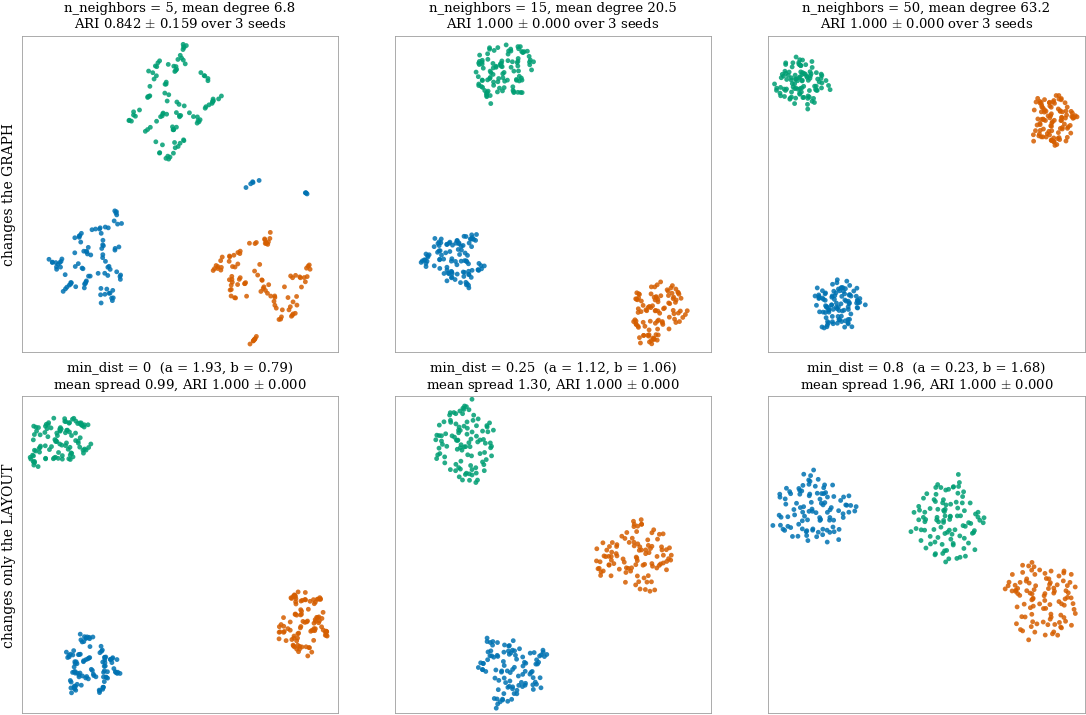


Every panel is drawn on a square window holding its central 99% of points, so the six
are comparable by eye; at n_neighbors = 5 the layout throws a few singletons outside it.


In [11]:

SEEDS_UM = (0, 1, 2)                          # <-- CHANGE ME (every ARI below is over these)

fig, axes = plt.subplots(2, 3, figsize=(11.2, 7.2))
print(f"n_neighbors -- rebuilds the GRAPH ({len(SEEDS_UM)} layout seeds each):")
for ax, k in zip(axes[0], (5, 15, 50)):       # <-- CHANGE ME
    Pk, _, _, _ = fuzzy_graph(X_um, n_neighbors=k)
    deg = float((Pk > 0).sum(1).mean())
    ars, sps, first = [], [], None
    for s in SEEDS_UM:
        Yk = umap_layout(Pk, n_epochs=300, a=a_um, b=b_um, seed=s)
        ars.append(adjusted_rand_score(y_um, KMeans(3, n_init=10, random_state=0).fit_predict(Yk)))
        sps.append(float(np.mean(spreads(Yk, y_um))))
        first = Yk if first is None else first
    ars, sps = np.array(ars), np.array(sps)
    scatter2d(ax, first, y_um, f"n_neighbors = {k}, mean degree {deg:.1f}\n"
                               f"ARI {ars.mean():.3f} $\\pm$ {ars.std(ddof=1):.3f} over "
                               f"{len(SEEDS_UM)} seeds")
    off = focus(ax, first)                    # a few strays must not set a panel's scale
    print(f"  k = {k:2d}: mean graph degree {deg:5.1f} | mean spread in the map "
          f"{sps.mean():.2f} +/- {sps.std(ddof=1):.2f} | ARI {ars.mean():.3f} +/- "
          f"{ars.std(ddof=1):.3f}  {np.round(ars, 3).tolist()}"
          + (f" | {off} points beyond the panel's 99th-percentile window" if off else ""))

print(f"\nmin_dist -- the SAME graph every time, only the layout target changes:")
for ax, md_ in zip(axes[1], (0.0, 0.25, 0.8)):
    am, bm = fit_ab(md_)
    ars, sps, first = [], [], None
    for s in SEEDS_UM:
        Ym = umap_layout(P_um, n_epochs=300, a=am, b=bm, seed=s)
        ars.append(adjusted_rand_score(y_um, KMeans(3, n_init=10, random_state=0).fit_predict(Ym)))
        sps.append(float(np.mean(spreads(Ym, y_um))))
        first = Ym if first is None else first
    ars, sps = np.array(ars), np.array(sps)
    scatter2d(ax, first, y_um, f"min_dist = {md_:g}  (a = {am:.2f}, b = {bm:.2f})\n"
                               f"mean spread {sps.mean():.2f}, ARI {ars.mean():.3f} $\\pm$ "
                               f"{ars.std(ddof=1):.3f}")
    off = focus(ax, first)
    print(f"  min_dist = {md_:4.2f}: a = {am:5.3f}, b = {bm:5.3f} | mean spread "
          f"{sps.mean():.2f} +/- {sps.std(ddof=1):.2f} | ARI still {ars.mean():.3f} +/- "
          f"{ars.std(ddof=1):.3f}"
          + (f" | {off} points beyond the panel's 99th-percentile window" if off else ""))
axes[0][0].set_ylabel("changes the GRAPH", fontsize=10)
axes[1][0].set_ylabel("changes only the LAYOUT", fontsize=10)
plt.show()
print("\nEvery panel is drawn on a square window holding its central 99% of points, so the six")
print("are comparable by eye; at n_neighbors = 5 the layout throws a few singletons outside it.")

The top row moves the graph and the bottom row does not, and the ARI column shows it. At
`n_neighbors = 5` the mean degree falls to **6.8**, the graph starts to fragment, and the
recovered partition degrades to **ARI $0.842\pm0.159$** over three layout seeds &mdash; $0.905$,
$0.961$, $0.661$. The answer changed, and it changed *differently every run*, which is worse than
one bad number: the mean spread in the map goes to **$2.09\pm0.61$** where `n_neighbors = 15`
holds **$1.11\pm0.01$**. At $k=5$ this layout is not merely wrong, it is unstable, and the panel
has to be drawn on a robust window because a few points are thrown clean out of it. At `15` and
`50` (degrees **20.5** and **63.2**) the partition is perfect again, **ARI $1.000\pm0.000$**, and
the map just gets tighter (mean spread **1.11** then **0.97**).

Along the bottom row `min_dist` swings the fitted curve hard &mdash; $a$ from **1.933** down to
**0.232**, $b$ from **0.790** up to **1.681** &mdash; and the mean spread with it, from **0.99** to
**1.96**. The ARI does not budge: **$1.000\pm0.000$** at every setting and every seed. That is the
definition of a presentation knob, and it is worth knowing which of your knobs are which.

## 10. One relative that is not about pictures at all: ICA

The lecture closes the "beyond PCA" family with **Independent Component Analysis**, and it is the
useful contrast to everything above. PCA, t-SNE and UMAP all answer *"draw me this cloud"*. ICA
answers a different question: **the data is a mixture, give me back the ingredients.**

The model is $\mathbf{x}=A\mathbf{s}$: each observation is an unknown linear mixture of
statistically **independent**, non-Gaussian **sources** $\mathbf{s}$. ICA estimates the unmixing
$W\approx A^{-1}$ by *maximizing non-Gaussianity* &mdash; a higher-order criterion, where PCA uses
only the second-order covariance. So ICA's components are **not** orthogonal and **not** ordered
by variance, and that is the point: orthogonality is exactly what PCA imposes and mixtures do not
obey.

The cocktail-party demonstration: three signals, three microphones, each recording a different
mixture. We score the result honestly, by the largest $|$correlation$|$ any recovered component
reaches with each true source (ICA fixes neither the order nor the sign), and we run PCA on the
same mixtures for comparison. One run would prove nothing here either, so the picture shows one
run and the table underneath it repeats the whole experiment over **three mixing matrices**
&times; **five fresh draws** of the sources.

largest |correlation| with each hidden source (1.0 = recovered exactly),
for the one run drawn below -- mixing A, draw 0:
                     sine   square  sawtooth     mean
ICA                0.9950   0.9997    0.9913   0.9954
PCA                0.7878   0.7667    0.6508   0.7351

and one run is not a finding: 3 mixing matrices x 5 fresh draws = 15 runs, mean |correlation| over the three sources, mean +/- sd
mixing               angles between its unmixing rows      ICA mean |corr|      PCA mean |corr|
A (drawn below)                49.2 / 68.6 / 24.0 deg     0.9951 +/-0.0006     0.7352 +/-0.0010
B                              58.6 / 61.9 / 75.3 deg     0.9950 +/-0.0006     0.7474 +/-0.0013
C                              80.6 / 86.9 / 80.4 deg     0.9950 +/-0.0006     0.8392 +/-0.0020
all runs                                                  0.9951 +/-0.0006     0.7739 +/-0.0481

ICA wins 15 of 15 runs -- its worst run is 0.9941, PCA's best is 0.8422.
PCA can only ever report unmixi

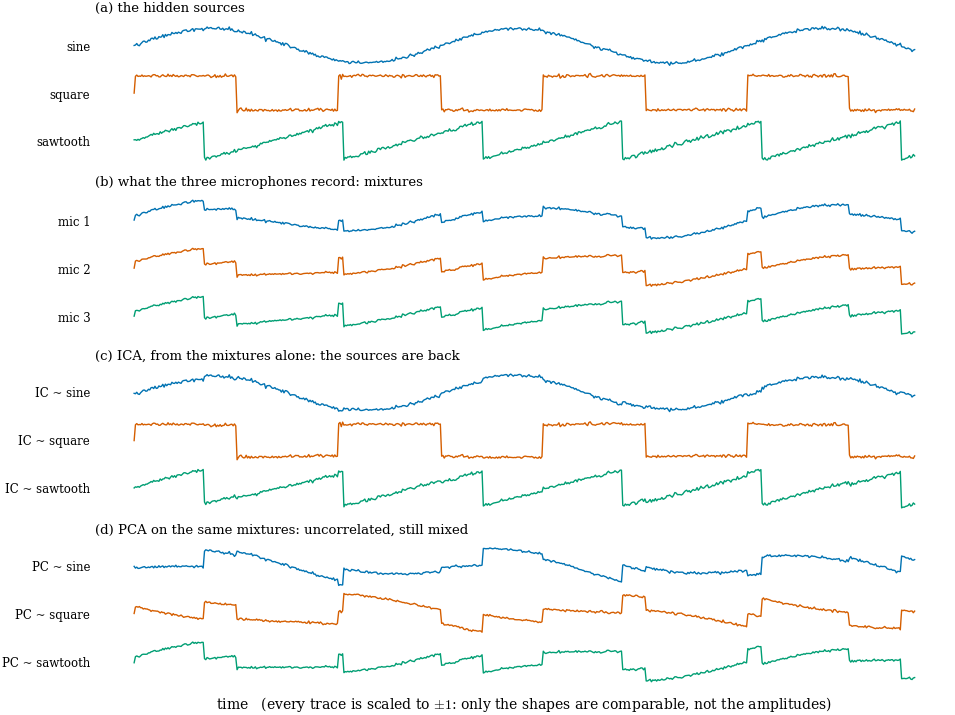

In [12]:
SEEDS_IC = (0, 1, 2, 3, 4)                    # <-- CHANGE ME (five fresh draws of the sources)
MIXES_IC = {                                  # <-- CHANGE ME: three (unknown) mixing matrices
    "A (drawn below)": np.array([[1.0, 0.6, 0.4],
                                 [0.5, 1.0, 0.7],
                                 [0.4, 0.8, 1.0]]),
    "B": np.array([[0.8, 0.3, 1.0],
                   [1.0, 0.9, 0.2],
                   [0.2, 1.0, 0.6]]),
    "C": np.array([[1.0, -0.7, 0.5],
                   [0.6, 1.0, -0.4],
                   [-0.3, 0.5, 1.0]])}


def sources(seed, n=600):
    "three independent, non-Gaussian signals: a sine, a square wave and a sawtooth"
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 8, n)
    S = np.column_stack([np.sin(2 * t),                                    # a sine
                         np.sign(np.sin(3 * t)),                           # a square wave
                         2 * (0.7 * t - np.floor(0.5 + 0.7 * t))])         # a sawtooth
    S = S + 0.05 * rng.standard_normal(S.shape)
    return t, S / S.std(0)


def unmix_ica(X, seed):
    "FastICA on the mixtures alone -- it never sees the sources"
    return FastICA(n_components=3, random_state=seed, max_iter=2000,
                   whiten="unit-variance").fit_transform(X)


def recovery(M, S):
    "for each true source, the largest |correlation| any component of M reaches"
    C = np.abs(np.corrcoef(M.T, S.T)[:M.shape[1], M.shape[1]:])
    return C.max(0)


def align(M, S):
    "reorder and sign-flip the columns of M to sit under the sources, for plotting only"
    C = np.abs(np.corrcoef(M.T, S.T)[:M.shape[1], M.shape[1]:])
    out, used = np.zeros_like(M), set()
    for j in range(S.shape[1]):
        k = int(max((i for i in range(M.shape[1]) if i not in used), key=lambda i: C[i, j]))
        used.add(k)
        out[:, j] = np.sign(np.corrcoef(M[:, k], S[:, j])[0, 1]) * M[:, k]
    return out


def row_angles(A):
    "the three angles between the rows of the TRUE unmixing matrix W = A^-1"
    W = np.linalg.inv(A)
    W = W / np.linalg.norm(W, axis=1, keepdims=True)
    return [float(np.degrees(np.arccos(min(1.0, abs(W[i] @ W[j])))))
            for i, j in ((0, 1), (0, 2), (1, 2))]


# the single run the figure draws: mixing A, draw 0
t_ic, S_ic = sources(SEEDS_IC[0])
A_ic = MIXES_IC["A (drawn below)"]
X_ic = S_ic @ A_ic.T                          # what the three microphones record
R_ic = unmix_ica(X_ic, SEEDS_IC[0])
Q_ic = PCA(n_components=3).fit_transform(X_ic)

print("largest |correlation| with each hidden source (1.0 = recovered exactly),")
print(f"for the one run drawn below -- mixing A, draw {SEEDS_IC[0]}:")
print(f"{'':16s} {'sine':>8s} {'square':>8s} {'sawtooth':>9s} {'mean':>8s}")
for nm, M in (("ICA", R_ic), ("PCA", Q_ic)):
    v = recovery(M, S_ic)
    print(f"{nm:16s} {v[0]:8.4f} {v[1]:8.4f} {v[2]:9.4f} {v.mean():8.4f}")

# ... and one run is not a finding. Every mixing matrix, every draw, scored the same way.
sc_ic = {}
for nm, A in MIXES_IC.items():
    ii, pp = [], []
    for s in SEEDS_IC:
        _, S = sources(s)
        X = S @ A.T
        ii.append(float(recovery(unmix_ica(X, s), S).mean()))
        pp.append(float(recovery(PCA(n_components=3).fit_transform(X), S).mean()))
    sc_ic[nm] = (np.array(ii), np.array(pp))

n_runs = len(MIXES_IC) * len(SEEDS_IC)
print(f"\nand one run is not a finding: {len(MIXES_IC)} mixing matrices x {len(SEEDS_IC)} fresh "
      f"draws = {n_runs} runs, mean |correlation| over the three sources, mean +/- sd")
print(f"{'mixing':18s} {'angles between its unmixing rows':>34s} {'ICA mean |corr|':>20s} "
      f"{'PCA mean |corr|':>20s}")
for nm, (ii, pp) in sc_ic.items():
    ang = " / ".join(f"{a:.1f}" for a in row_angles(MIXES_IC[nm])) + " deg"
    print(f"{nm:18s} {ang:>34s} {ii.mean():10.4f} +/-{ii.std(ddof=1):6.4f} "
          f"{pp.mean():10.4f} +/-{pp.std(ddof=1):6.4f}")
allI = np.concatenate([v[0] for v in sc_ic.values()])
allP = np.concatenate([v[1] for v in sc_ic.values()])
print(f"{'all runs':18s} {'':>34s} {allI.mean():10.4f} +/-{allI.std(ddof=1):6.4f} "
      f"{allP.mean():10.4f} +/-{allP.std(ddof=1):6.4f}")

print(f"\nICA wins {int((allI > allP).sum())} of {n_runs} runs -- its worst run is "
      f"{allI.min():.4f}, PCA's best is {allP.max():.4f}.")
print("PCA can only ever report unmixing directions 90.0 degrees apart, so ITS score is set by")
print(f"the mixing: it does best on C, whose rows are nearly orthogonal already, and worst on A,")
print(f"the one drawn below, whose first two unmixing rows sit {row_angles(A_ic)[0]:.1f} degrees "
      f"apart. ICA barely moves.")


def stack(ax, M, title, names):
    "three traces, offset and each scaled to +/-1 -- only the SHAPES are being compared"
    off = [(1 - k) * 2.4 for k in range(3)]
    for k in range(3):
        d = M[:, k] / (np.abs(M[:, k]).max() + 1e-12)
        ax.plot(t_ic, d + off[k], color=[C0, C1, CG][k], lw=1.0)
    ax.set_title(title, fontsize=9.5, loc="left")
    ax.set_xticks([]); ax.grid(False)
    ax.set_yticks(off, names, fontsize=8.5)          # say which trace is which
    ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)


fig, axes = plt.subplots(4, 1, figsize=(9.6, 7.2))
stack(axes[0], S_ic, "(a) the hidden sources", ["sine", "square", "sawtooth"])
stack(axes[1], X_ic, "(b) what the three microphones record: mixtures",
      ["mic 1", "mic 2", "mic 3"])
stack(axes[2], align(R_ic, S_ic), "(c) ICA, from the mixtures alone: the sources are back",
      ["IC ~ sine", "IC ~ square", "IC ~ sawtooth"])
stack(axes[3], align(Q_ic, S_ic), "(d) PCA on the same mixtures: uncorrelated, still mixed",
      ["PC ~ sine", "PC ~ square", "PC ~ sawtooth"])
axes[3].set_xlabel("time   (every trace is scaled to $\\pm1$: only the shapes are comparable, "
                   "not the amplitudes)")
plt.show()


## Recap & exercises

**Recap.**

* A **linear** map can only rotate and project, so on a curved sheet it cannot measure distance
  *along* the surface. Over **five fresh swiss rolls** PCA's global score is $\rho=0.372\pm0.016$
  and the raw 3-D data's own is $0.372\pm0.017$ &mdash; a projection inherits the metric it is
  given. Being *nonlinear* is not the cure: kernel PCA is worse still, $0.255\pm0.008$. What fixes
  it is measuring distance along a neighbor **graph** &mdash; Isomap at `n_neighbors=6` reaches
  $0.997\pm0.002$ &mdash; and the graph has to be right: at `n_neighbors=20` it short-circuits
  between turns and falls to $0.346\pm0.036$, no better than PCA.
* The tempting headline &mdash; "what share of points get a map-neighbor more than 20 units away
  along the sheet" &mdash; is **not** quotable, and this notebook says so out loud. PCA folds
  $13.5\%$ of them on one draw and $0.0\%$ on another, $5.2\%\pm5.0\%$ over five. A statistic
  that survives reseeding is a finding; one that does not is a coincidence with a decimal point.
* t-SNE is the best *local* map and among the weakest at global geometry: trustworthiness
  $0.999\pm0.000$, matching the raw 3-D data's own $0.999\pm0.001$, against $\rho=0.515\pm0.059$
  where Isomap gets $0.997$.
* **Kernel PCA** is Session&nbsp;07's Gram matrix doing Session&nbsp;11's job: on two concentric
  rings the best single threshold goes from $0.6890\pm0.0029$ on PC1 &mdash; no better than the
  raw coordinate's $0.6900\pm0.0018$, and to be read against a shuffled-label null of
  $0.5423\pm0.0132$ rather than $0.5$ &mdash; to $1.0000\pm0.0000$ on kPC1. The price is in the
  picture: in the data the **outer** ring's box is $6.96\times$ the inner one's, and at
  $\gamma=8$ the map draws it $119\times\pm19$ **smaller**, a swing of about $826\times$ with
  the comparison reversed. Areas in that map are not areas. (What $\gamma$ does to a Gram matrix
  was measured in Session&nbsp;10b, section&nbsp;8.)
* **Perplexity** is one number that sets $n$ bandwidths, by binary search on
  $\mathrm{Perp}=2^{H}$. On seven points it gave $\sigma$ from $0.0476$ to $2.8238$ &mdash; a factor
  of **59** &mdash; and matched scikit-learn's own search to $8.5\times10^{-6}$.
* Perplexity is a local/global dial with no right value. On data with **3** real clusters,
  perplexity $2$ drew **28&ndash;29** clumps over three seeds; on data with **no** clusters it drew
  **21**. From one picture you cannot tell those apart. At perplexity $30$ the three-cluster data
  gives **3** clumps at every seed and at every sensible detector radius &mdash; but the pure noise
  still gives **1&ndash;4**, so the rule needs both halves: several perplexities **and** several
  seeds.
* The map kernel is a **Student-$t$** because of **crowding**: 11 mutually equidistant 10-D
  points cannot be flattened to better than a **3.28&times;** spread, and at similarity $0.01$ the
  heavy tail grants **4.64&times;** more distance than a Gaussian would. A kernel chosen to
  distort distances does not then report distances.
* **Sizes and gaps both go.** Clusters built with a **24.8&times;** size ratio and a
  **5.0&times;** gap ratio came back as $0.995\times$ and $0.987\times$ &mdash; and as
  $0.998\times\pm0.002$ and $0.970\times\pm0.046$ over three random-init seeds, so it is the
  method and not the init.
* **Coordinates are not reproducible** (Procrustes disparity $0.694$&ndash;$0.763$ across seeds,
  **58&ndash;64%** shared neighbors) even where the *partition* is perfectly reproducible (ARI
  $1.000$ every time). Only about **half** of a point's ten true neighbors are its ten neighbors in
  the map. `TSNE` has **no** `.transform`; `Isomap` does.
* **UMAP** is the same two forces in different bookkeeping: a fuzzy $k$-NN graph ($\sigma_i$
  calibrated so memberships sum to $\log_2 k$; ours hit $3.906891$ against the target $3.906891$,
  with $\sigma_i$ spanning **27&times;**) laid out by attraction on sampled edges and repulsion on
  random non-edges (our fitted $a=1.5769,\,b=0.8951$ against the package's $1.577,\,0.895$).
  **`n_neighbors`** rebuilds the graph &mdash; degree **6.8** to **63.2**, and at $5$ the partition
  itself degrades to **ARI $0.842\pm0.159$** over three layout seeds ($0.905$, $0.961$, $0.661$);
  **`min_dist`** only reshapes the layout target ($a$ from $1.933$ to $0.232$) and left the
  partition at **ARI $1.000\pm0.000$** throughout. Its size warning is
  t-SNE's: **2.98&times;** in the data, **1.02&ndash;1.09&times;** in the map.
* **ICA** answers a different question, and answers it well. Over **three mixing matrices
  &times; five fresh draws** it recovered the three sources from the mixtures alone at mean
  $|$correlation$|$ $0.9951\pm0.0006$, against PCA's $0.7739\pm0.0481$ on the same mixtures
  &mdash; and it won **all 15 runs**: ICA's worst, $0.9941$, still clears PCA's best, $0.8422$.
  The single run drawn in &sect;10 is $0.9954$ against $0.7351$. PCA can only report *orthogonal*
  directions, so **PCA's** score is the one set by the mixing: $0.8392\pm0.0020$ where the true
  unmixing rows are nearly orthogonal already ($80.6/86.9/80.4$ degrees), down to
  $0.7352\pm0.0010$ for the matrix drawn there, whose first two rows sit **49.2 degrees** apart.
  ICA's own score barely moves.

**The rule &mdash; what one of these pictures is evidence of.**

| a t-SNE / UMAP map **is** evidence of | it is **not** evidence of |
|---|---|
| which points sit near which, *approximately* | that two points are nearest neighbors |
| how many groups seem to be present &mdash; **if** the count survives several perplexities / `n_neighbors` and several seeds | that a cluster is real, from one run at one setting |
| that a group is separable in the original space (check it there, with a classifier or a clustering score) | that two clusters are far apart, or that one is bigger, denser or more diverse |
| a picture to *look* at | coordinates to compute with: never feed them to a model, a distance, or a statistical test |

The discipline that follows: **measure in the original space, and illustrate in the map.** If a
claim matters &mdash; these groups differ, this point is an outlier, that batch effect is gone &mdash;
support it with a number computed on $\mathbf{X}$, and use the 2-D picture only to show the
reader what you mean.

**Exercises.**

1. In &sect;1, the Isomap sweep already shows the short circuit appearing between $k=6$ and
   $k=12$. Now raise `noise=0.05` to `noise=1.0` inside `roll()` and repeat it over the same five
   seeds: at which $k$ does the graph short-circuit *now*, and why did more noise move it? Then
   explain why the same failure does not hurt t-SNE's **local** score.
2. In &sect;2, sweep `GAMMA_KP` finely between $1$ and $20$ and plot **both** the threshold
   accuracy and the inner/outer area ratio against $\gamma$. Explain both shapes: what does a
   kernel that is too wide lose, what does one that is too narrow lose, and why does the area
   ratio keep moving over a range where the accuracy does not? Then say which of the two curves
   you would be willing to put in a paper.
3. In &sect;4, add perplexity $200$ to `PERPS` (it must stay below $n=250$). The clump count is
   already right at $30$ &mdash; watch what the neighbor score does instead, and say what a very
   large perplexity is actually costing you. Then rerun the whole sweep with `init="pca"`: you will
   find the three seeds give *identical* answers. Explain why, and say what that does (and does
   not) tell you about stability.
4. In &sect;6, raise the gap ratio to $20\times$ (`gaps=(60.0, 1200.0)`) and then to $100\times$.
   Does the map ever show it? Also drop the size ratio to $1:2:4$ &mdash; is there a ratio small
   enough that the map reports it?
5. In &sect;7, re-run the three seeds with `init="pca"`. How much of the run-to-run variability was
   really the initialization? (This is the Kobak &amp; Linderman point from the lecture.)
6. **Give our UMAP a `transform`.** For a new point, find its $k$ nearest *training* points and
   place it at the membership-weighted average of their layout positions. Try it on twenty
   held-out points and compare with refitting everything &mdash; this is, in outline, what
   `umap-learn` does and what t-SNE cannot.
7. In &sect;9, run `fuzzy_graph(X_um, n_neighbors=3)` and look at the layout (it works down to
   $k=2$, where the target $\log_2 k$ is $1$). Where does fragmenting the graph stop being a knob
   and start being a different dataset? Use the ARI, not your eye.
8. In &sect;10, make one source Gaussian instead of a square wave and re-score. ICA's assumption
   is non-Gaussian sources &mdash; watch which component it fails to recover, and by how much.

*Next session: **neural networks** &mdash; and the first model in this course that learns its own
representation instead of being handed one.*